# Mono-$Z$ karanlık madde araması: veri, kurulum, BDT/DNN/NSF karşılaştırması

**TÜBİTAK 2209-A ara rapor defteri.** CMS Open Data (`RunIIFall15MiniAODv2`,
$\sqrt{s}=13$ TeV, $\mathcal{L}=2.32$ fb$^{-1}$) üzerinde
$pp\to Z\chi\bar\chi$, $Z\to\ell^+\ell^-$ kanalı.

Üç sınıflandırıcı **aynı olayları, aynı öznitelikleri, aynı bölünmeleri ve aynı
tohumları** kullanır; tek fark olabilirlik oranının nasıl kestirildiğidir:

| Yöntem | Kestirilen nicelik | Tür |
| --- | --- | --- |
| BDT | $p(S\mid x)$ | ayırt edici (discriminative) |
| DNN | $p(S\mid x)$ | ayırt edici |
| NSF | $p(x\mid S)$ ve $p(x\mid B)$ ayrı ayrı | üretici (yoğunluk kestirimi) |

Neyman–Pearson lemması en güçlü testin olabilirlik oranı
$\Lambda(x)=p(x\mid S)/p(x\mid B)$ ile verildiğini söyler. Ayırt edici modellerde bu
oran sınıf sonsalından, sabit öncellerle, tersine çevrilerek elde edilir:

$$\Lambda(x)=\frac{p(S\mid x)}{1-p(S\mid x)}\cdot\frac{1-\pi}{\pi},
\qquad
s_{\rm NSF}(x)=\log p(x\mid S)-\log p(x\mid B)=\log\Lambda(x)$$

*Kaynak:* J. Neyman, E. S. Pearson, Phil. Trans. R. Soc. A **231** (1933) 289;
K. Cranmer, J. Pavez, G. Louppe, arXiv:1506.02169.


## 0. Veri kaynağı

Girdilerin tamamı CERN Open Data Portal'dan alınan `RunIIFall15MiniAODv2` campaign'i
`MINIAODSIM` örnekleridir (2015, $\sqrt{s}=13$ TeV $pp$; koşul etiketi
`PU25nsData2015v1_76X_mcRun2_asymptotic_v12`; `CMSSW_7_6_7`). Gerçek çarpışma verisi
kullanılmamıştır.

| Rol | Veri kümesi | Kayıt | Dosya | $\sigma$ [pb] |
| --- | --- | --- | ---: | ---: |
| arka plan | `DYJetsToLL_M-50` (aMC@NLO) | [16458](https://opendata.cern.ch/record/16458) | 10 | 5932 |
| arka plan | `ZZTo2L2Nu` (POWHEG) | [21593](https://opendata.cern.ch/record/21593) | 2 | 0.5644 |
| arka plan | `WZTo3LNu` (POWHEG) | [20687](https://opendata.cern.ch/record/20687) | 3 | 4.102 |
| arka plan | `TTTo2L2Nu` (POWHEG) | [19958](https://opendata.cern.ch/record/19958) | 2 | 76.69 |
| arka plan | `ST_tW_top_5f` (POWHEG) | [19419](https://opendata.cern.ch/record/19419) | 3 | 38.09 |
| arka plan | `ST_tW_antitop_5f` (POWHEG) | [19412](https://opendata.cern.ch/record/19412) | 3 | 38.06 |
| sinyal | `MonoZToLL_A_Mx-10_Mv-20` | [16575](https://opendata.cern.ch/record/16575) | 1 | 1.856 |
| sinyal | `MonoZToLL_A_Mx-50_Mv-200` | [16597](https://opendata.cern.ch/record/16597) | 3 | 0.158 |
| sinyal | `MonoZToLL_V_Mx-1_Mv-500` | [16630](https://opendata.cern.ch/record/16630) | 1 | 0.0273 |
| sinyal | `MonoZToLL_EWK_Scalar_Mx-100_Lambda-3000` | [16601](https://opendata.cern.ch/record/16601) | 1 | $9.9\times10^{-8}$ |

Sinyal DOI'leri: `10.7483/OPENDATA.CMS.{YB3Q.XTXY, 34IE.KN6I, YTLH.E0N7, NW7F.NFGG}`.

**Kaynak seçimi.** `DarkMatter_MonoZToLL` örnekleri yalnızca `RunIIFall15` campaign'inde
yayımlanmıştır; Run-2 Ultra-Legacy'de arka planların karşılığı bulunsa da bu sinyal ailesi
yoktur (UL16'daki karanlık madde örnekleri `DM_MonoZPrime`, farklı bir modeldir). Sinyal ve
arka planın aynı campaign'den seçilmesi, pile-up profili ve rekonstrüksiyon sürümünün ortak
olmasını sağlar. MINIAOD formatı gerekli PAT nesnelerini içerir; bu campaign'in NanoAOD'u
yayımlanmamıştır. Dört sinyal noktası referans analizle (Rasineni & Chebrolu, Tablo 5)
örtüşmektedir. Dosya bütünlüğü `adler32` ile doğrulanır (`_indir.py`); kullanılan dosyaların
listesi `_dosyalar.json` içindedir.

**Üretici farkı tutarsızlık değildir.** DY `amcatnloFXFX`, diğer beş arka plan
`powheg` ile üretilmiştir; bu CMS'in sürece özgü standart seçimidir --
Drell--Yan çok-jet birleştirme (FxFx) gerektirir, diboson/$t\bar t$/$tW$
gerektirmez. Tam veri kümesi adları doğrulandı: hepsi aynı `pythia8` parton
gölgelemesini ve aynı `RunIIFall15MiniAODv2-PU25nsData2015v1_76X_mcRun2_asymptotic_v12`
campaign etiketini taşıyor (DY'de `_ext4` soneki yalnızca ek istatistik üretimi
anlamına gelir, koşulları değiştirmez).

**Süreç kapsamı.** Mono-$Z$ imzası iki ters yüklü aynı tatta lepton ve $E_T^{\rm miss}$'tir.
$ZZ\to2\ell2\nu$ indirgenemezdir. $WZ\to3\ell\nu$, bir lepton kaybedildiğinde indirgenemez
hâle gelir. Drell–Yan'da gerçek $E_T^{\rm miss}$ bulunmaz; ancak tesir kesiti $10^3$–$10^4$
kat büyük olduğundan çözünürlükten doğan sahte $E_T^{\rm miss}$ kuyruğu baskın arka planı
oluşturur. $t\bar t$, $tW$ ve $\bar tW$ iki gerçek $W\to\ell\nu$ içerir ve $Z$ kütle
penceresiyle kısmen bastırılır. Tek lepton sahteleri ($W$+jet, QCD) izolasyon ve kütle
penceresi sonrası ihmal edilebilir düzeydedir.


## 1a. Olay ağırlığı ve tesir kesiti normalizasyonu

$$w \;=\; w_{\rm gen}\cdot
\frac{\sigma_{\rm pb}\,\mathcal{L}_{\rm fb^{-1}}\times 1000}{\sum w_{\rm gen}}
\cdot w_{\rm PU}\cdot SF_{\mu_1}\cdot SF_{\mu_2},
\qquad w_{\rm data}=1$$

$\sigma\mathcal{L}\times1000$ çarpımı beklenen olay sayısını verir; $1000$ katsayısı
$\mathcal{L}$'yi fb$^{-1}$'den pb$^{-1}$'ye çevirerek çarpımı boyutsuz kılar. Payda
$\sum w_{\rm gen}$ kesim öncesi tüm olaylar üzerinden alınır. $w_{\rm gen}/\sum w_{\rm gen}$
oranı olayın örnek içindeki payıdır; beklenen olay sayısı bu payla ölçeklendiğinde tek bir MC
olayının temsil ettiği gerçek olay sayısı elde edilir.

$\mathcal{L}=2.32$ fb$^{-1}$ için:

| Örnek | $\sigma$ [pb] | $\sum w_{\rm gen}$ | $N_{\rm gen}$ | $\sigma\mathcal{L}$ | olay başına |
| --- | ---: | ---: | ---: | ---: | ---: |
| DY | 5932 | $7.83\times10^{9}$ | 497 974 | $1.38\times10^{7}$ | 41.21 |
| $ZZ$ | 0.5644 | $6.30\times10^{4}$ | 63 025 | 1 310 | 0.0208 |
| $WZ$ | 4.102 | $9.52\times10^{4}$ | 95 164 | 9 516 | 0.1000 |
| $t\bar t$ | 76.69 | $5.62\times10^{4}$ | 56 227 | 177 921 | 3.164 |
| $tW$ | 38.09 | $1.06\times10^{5}$ | 105 600 | 88 369 | 0.8368 |
| $\bar tW$ | 38.06 | $1.10\times10^{5}$ | 110 000 | 88 299 | 0.8027 |
| A$(10,20)$ | 1.856 | $5.0\times10^{4}$ | 50 000 | 4 306 | 0.0861 |
| A$(50,200)$ | 0.158 | $5.0\times10^{4}$ | 50 000 | 367 | 0.0073 |
| V$(1,500)$ | 0.0273 | $5.0\times10^{4}$ | 50 000 | 63 | 0.0013 |

DY ile $ZZ$ arasındaki olay başına ağırlık oranı $\sim2\times10^{3}$'tür. Bu fark üç sonuç
doğurur: (i) DY histogramlarda kesikli görünür, her olay $41$ birimlik bir katkı yapar;
(ii) etkin örneklem büyüklüğü $N_{\rm eff}$ düşer ve anlamlılık taraması ham olay sayısı
yerine $N_{\rm eff}$ ile korunmalıdır (§13); (iii) DY belirsizliği baskın sistematik olur.

**Üretici ağırlıkları.** DY tek `amcatnloFXFX` örneğidir ve olaylarının %16.5'i negatif
ağırlıklıdır; $\lvert w_{\rm gen}\rvert$ 497 974 olayın tamamında tek bir değer alır
(23 443.4). Negatif ağırlıklar NLO eşleştirmede çift sayımı önler. Ölçülen
$\sum w_{\rm gen}/N_{\rm gen}=0.668$ oranı işaret dengesinden gelir: $1-2(0.165)=0.670$.
Diğer beş arka plan (POWHEG) ve dört sinyal (MADGRAPH) örneğinde $w_{\rm gen}\equiv1$'dir.

**Ölçek çarpanları.** $w_{\rm PU}$ ve $SF_\mu$ bu çalışmada $1$ alınmıştır. Her iki çarpanın
işlevi simülasyonu veriye uyarlamaktır; gerçek veri kullanılmadığından referans yoktur.
Ayrıca sinyal ve arka plana aynı yönde uygulandıkları için $S/B$ oranında ve dolayısıyla
$Z_A$'da büyük ölçüde sadeleşirler. Veri/MC karşılaştırması veya veri üzerinden mutlak limit
çıkarımı yapılması hâlinde gerekli olurlar.

*Kaynak:* N. Bostan, *Event Weight Summary* (grup sunumu). Uygulama: `_extract.py`
(`generator_weights`, `load`); ölçüm: `_dy_tani2.py`.


In [44]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import uproot
import awkward as ak
import zuko
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import log_loss, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

LUMI = 2320.0          # pb^-1, CMS Run 2015D
MZ = 91.1876           #GeV/c^2
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT = '/work/results/'
exec(open('/work/_extract.py').read())   # load, BKG, SIG, cell_resample

print('arka planlar :', list(BKG.keys()))
print('sinyaller    :', list(SIG.keys()))

arka planlar : ['DY', 'ZZ', 'WZ', 'ttbar', 'tW_top', 'tW_antitop']
sinyaller    : ['axial (10, 20)', 'axial (50, 200)', 'vector (1, 500)', 'scalar (100, 3000)']


## 1a-2. $ZZ$ üzerinden bir bakış

In [45]:
zz = load({'ZZ': BKG['ZZ']})

print('boyut (olay, sutun):', zz.shape)
print()
for i, c in enumerate(zz.columns, start=1):
    print(f'{i:2d}. {c}')
print()
print(zz[['met', 'Z_pt', 'm_ll', 'dphi_Z_met', 'n_jets', 'weight']].head())
print()
print(zz[['met', 'm_ll', 'dphi_Z_met', 'n_jets']].describe().round(2))


ZZ                 N_gen=  63025  sum_w=  63025.0  selected= 17856  sigma=   0.5644 pb  yield=    371.0  [onbellek]
boyut (olay, sutun): (17856, 40)

 1. met
 2. met_phi
 3. min_dphi_met_jets
 4. dphi_met_jet1
 5. dphi_met_jet2
 6. met_over_sqrtHT
 7. hadronic_recoil_pt
 8. m_ll
 9. Z_pt
10. Z_eta
11. Z_phi
12. dphi_Z_met
13. met_over_ptZ
14. abs_met_minus_ptZ
15. abs_mll_minus_mZ
16. u_parallel
17. u_perp
18. u_parallel_over_ptZ
19. u_perp_over_ptZ
20. lep1_pt
21. lep1_eta
22. lep2_pt
23. lep2_eta
24. dR_ll
25. dphi_ll
26. lep1_reliso
27. lep2_reliso
28. cos_theta_star
29. dphi_met_lep1
30. jet1_pt
31. jet1_eta
32. jet2_pt
33. jet2_eta
34. has_jet1
35. has_jet2
36. n_jets
37. mT
38. w_gen
39. weight
40. process

          met        Z_pt       m_ll  dphi_Z_met  n_jets    weight
0   70.712807   87.587038  90.967536    2.899987       0  0.000009
1   54.893635   51.504695  91.447124    2.955057       0  0.000009
2  102.147560  129.080988  93.270671    3.132290       0  0.000009
3   33.18

## 1a-3. $ZZ$  ve $Mono-Z$ gözlemlenebilirlerinin karşılaştırılması

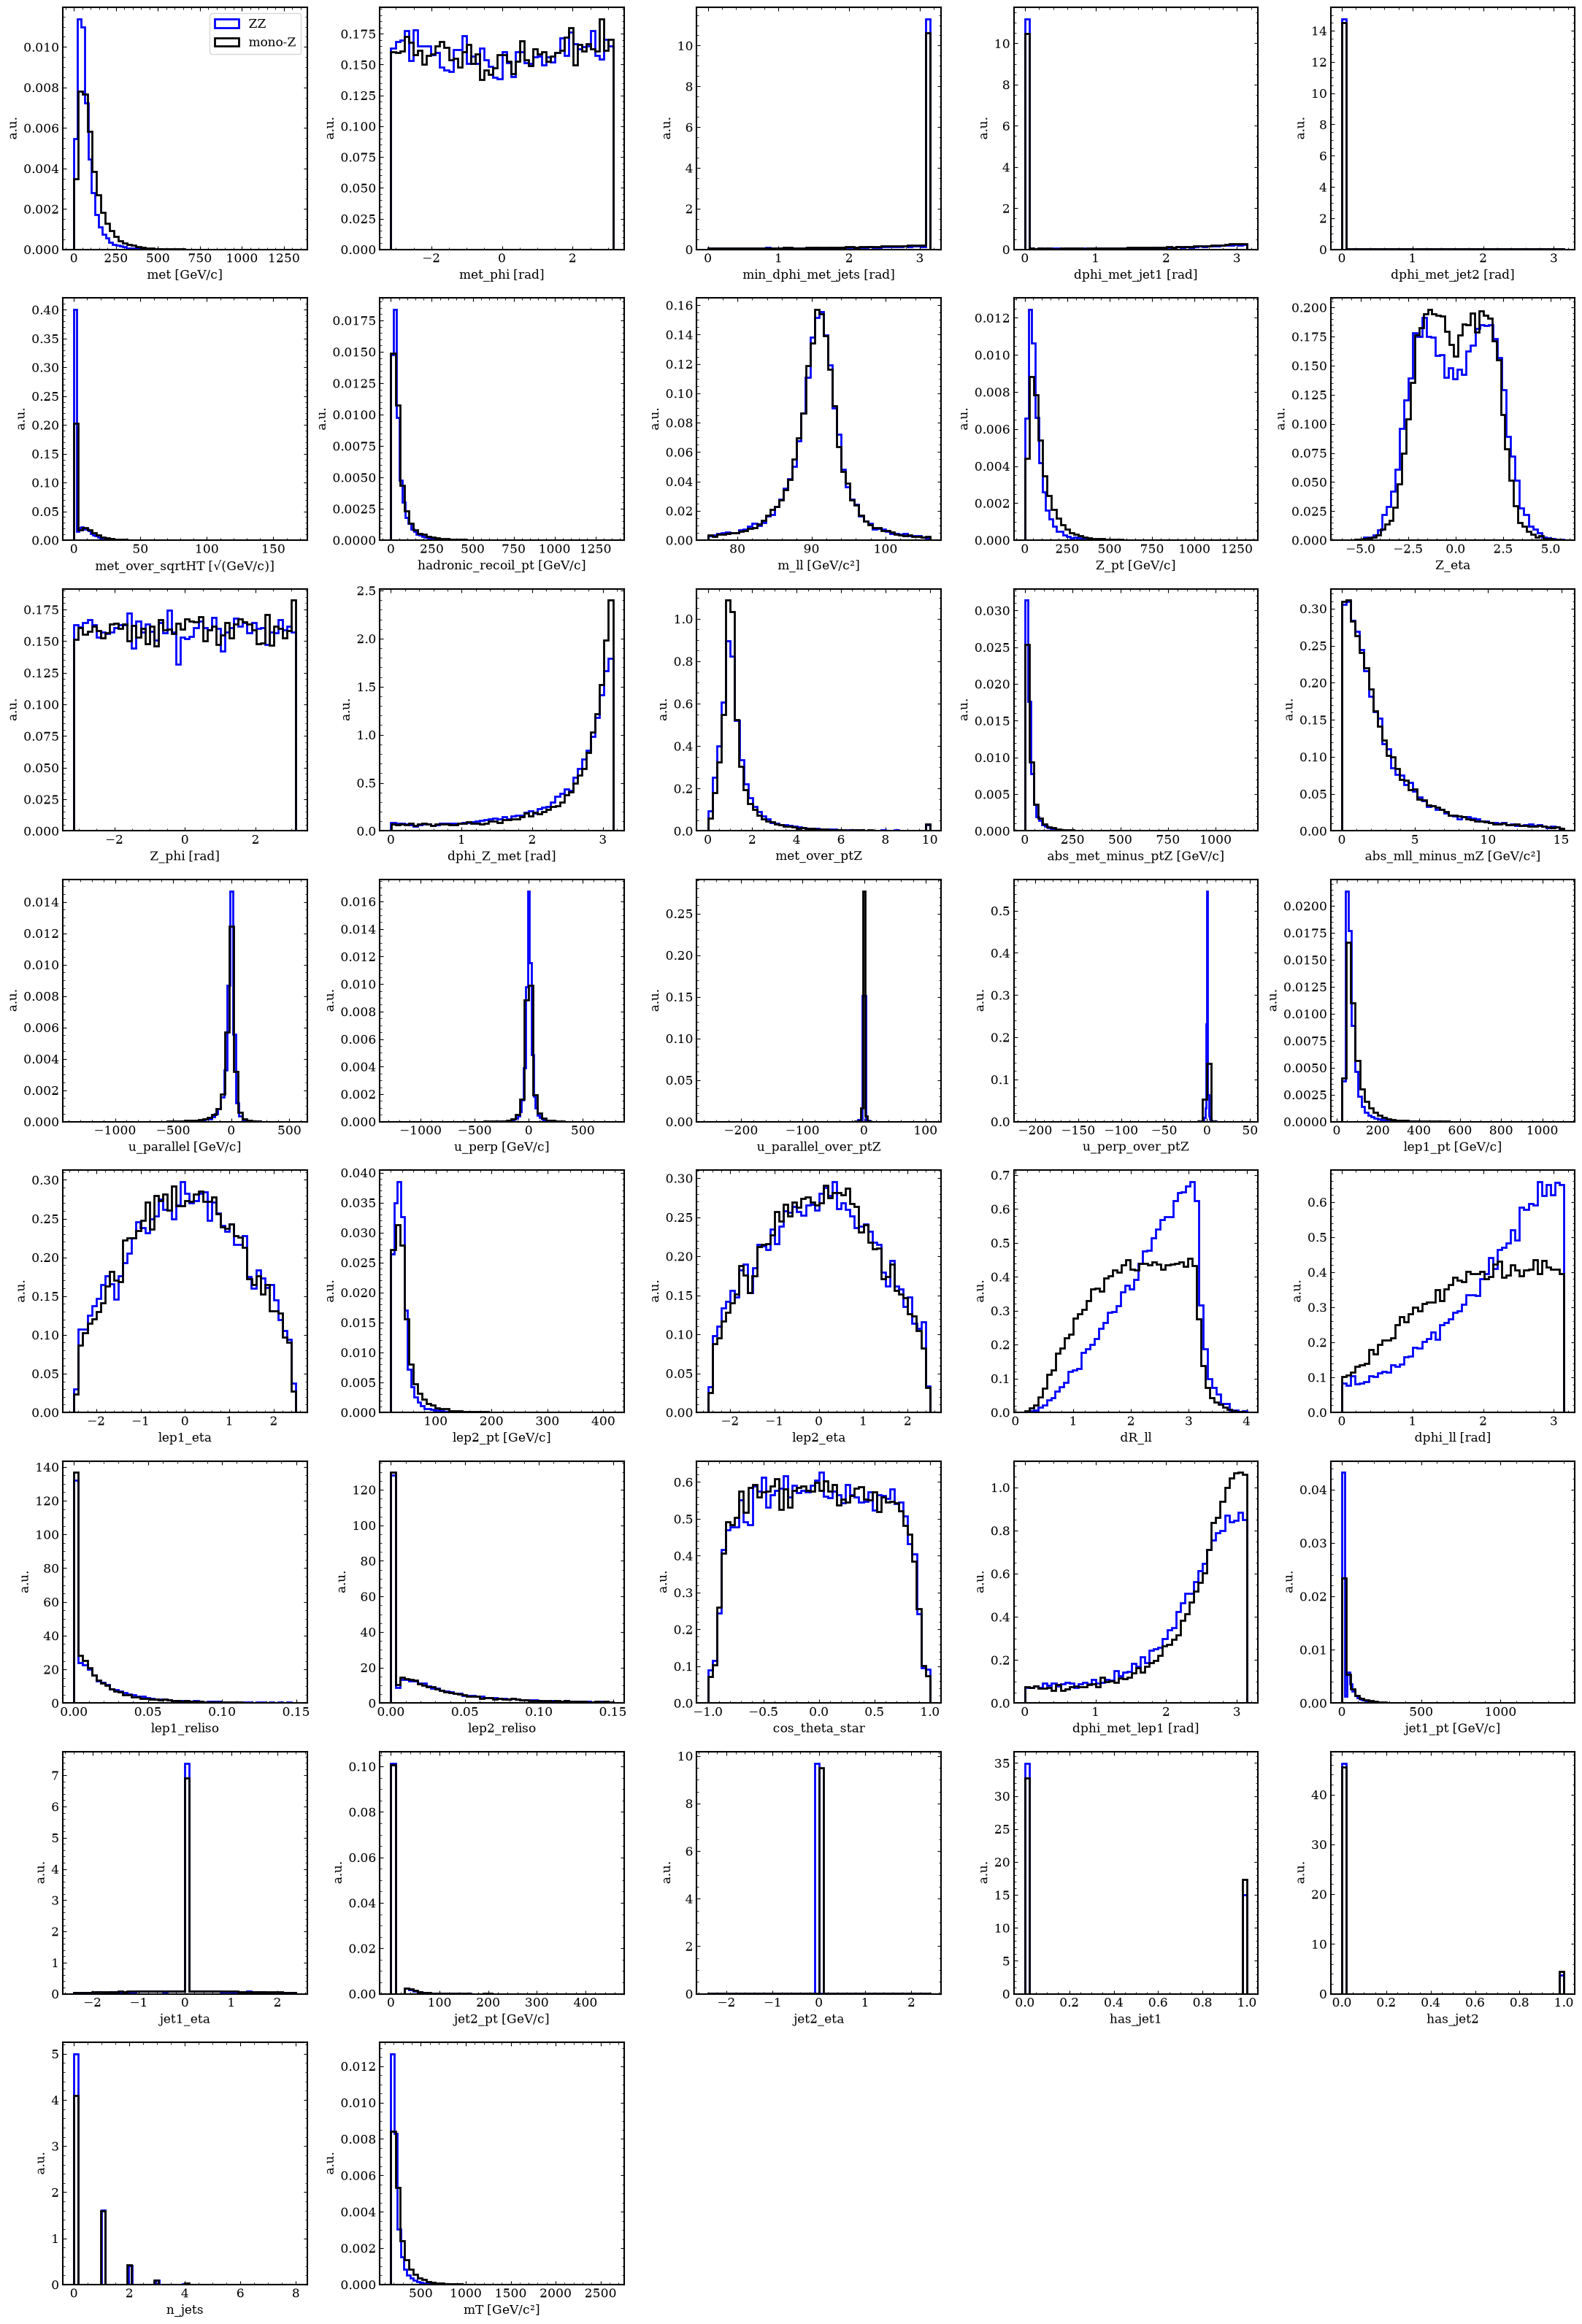

In [26]:
plt.rcParams.update({
    'xtick.direction': 'in', 'ytick.direction': 'in',   # centikler ice donuk
    'xtick.top': True, 'ytick.right': True,             # dort kenarda centik
    'xtick.minor.visible': True, 'ytick.minor.visible': True,
    'axes.linewidth': 1.5,                              # kalin cerceve
    'font.family': 'serif', 'font.size': 12,
    'axes.grid': False,
})

fig, ax = plt.subplots(8, 5, figsize=(22, 32))
for a, f in zip(ax.flat, F):
    a.hist(zz[f], bins=50, density=True, histtype='step', lw=2, color='blue', label='ZZ')
    a.hist(mz[f], bins=50, density=True, histtype='step', lw=2, color='black', label='mono-Z')
    a.set_xlabel(f'{f} [{BIRIM[f]}]' if f in BIRIM else f)
    a.set_ylabel('a.u.')
ax[0, 0].legend()
for a in ax.flat[len(F):]:
    a.axis('off')
plt.tight_layout()
plt.show()

### 1.a 4.Öznitelik envanteri

Sinyal bölgesindeki arka plan olaylarında bulunan bütün sayısal değişkenler listelenir (`weight` hariç). Her değişken için aralık (min, medyan, max) ve kaç farklı değer aldığı gösterilir. Bu sayıya göre değişkenler üç türe ayrılır:

| Tür | Farklı değer sayısı | Anlamı |
| --- | --- | --- |
| sabit | 1 | Her olayda aynı; bilgi taşımaz, elenir |
| ayrık | 2–10 | Sayım veya evet/hayır (ör. `n_jets`) |
| sürekli | >10 | Ölçülen büyüklük (ör. `met`, `Z_pt`) |

Sabit değişkenler sonraki adımlarda kullanılmaz. Ayrık değişkenler NSF eğitiminde dequantize edilir.

In [49]:
F = [c for c in bkg.select_dtypes(include='number').columns if c != 'weight']

ozet = pd.DataFrame({
    'min':              bkg[F].min(),
    'medyan':           bkg[F].median(),
    'max':              bkg[F].max(),
    'farkli_deger_sayisi': bkg[F].nunique(),
})

def tur(n):
    if n == 1:
        return 'SABIT (at)'
    if n <= 10:
        return 'ayrik'
    return 'surekli'

ozet['tur'] = ozet['farkli_deger_sayisi'].apply(tur)

print(f'{len(F)} oznitelik\n')
print(ozet.round(2).to_string())
print('\nsabit olanlar:', ozet.index[ozet.tur == 'SABIT (at)'].tolist())

38 oznitelik

                          min  medyan       max  farkli_deger_sayisi         tur
met                     50.00   76.36    725.10                 9808     surekli
met_phi                 -3.14   -0.01      3.14                 9812     surekli
min_dphi_met_jets        0.00    3.14      3.14                 2384     surekli
dphi_met_jet1            0.00    0.00      3.14                 2384     surekli
dphi_met_jet2            0.00    0.00      0.00                    1  SABIT (at)
met_over_sqrtHT          0.00    0.00     88.67                 2384     surekli
hadronic_recoil_pt       0.41   29.50    372.98                 9812     surekli
m_ll                    76.12   90.94    105.90                 9812     surekli
Z_pt                     0.16   69.83    652.40                 9812     surekli
Z_eta                   -6.05    0.00      5.68                 9804     surekli
Z_phi                   -3.14    0.00      3.14                 9812     surekli
dphi_Z_met    

### Değişken dağılımları: sinyal ve arka plan

Sabit olmayan her öznitelik için sinyal (mono-Z) ve arka plan dağılımları birim alana normalize edilerek üst üste çizilir. Eğrilerin ayrıştığı değişkenler ayırt edici öznitelik adaylarıdır. İki arka plan çizgisi vardır:
- **ZZ:** sinyale en çok benzeyen, indirgenemez arka plan,
- **tüm arka plan:** fiziksel verimle ağırlıklı karışım; DY baskın.

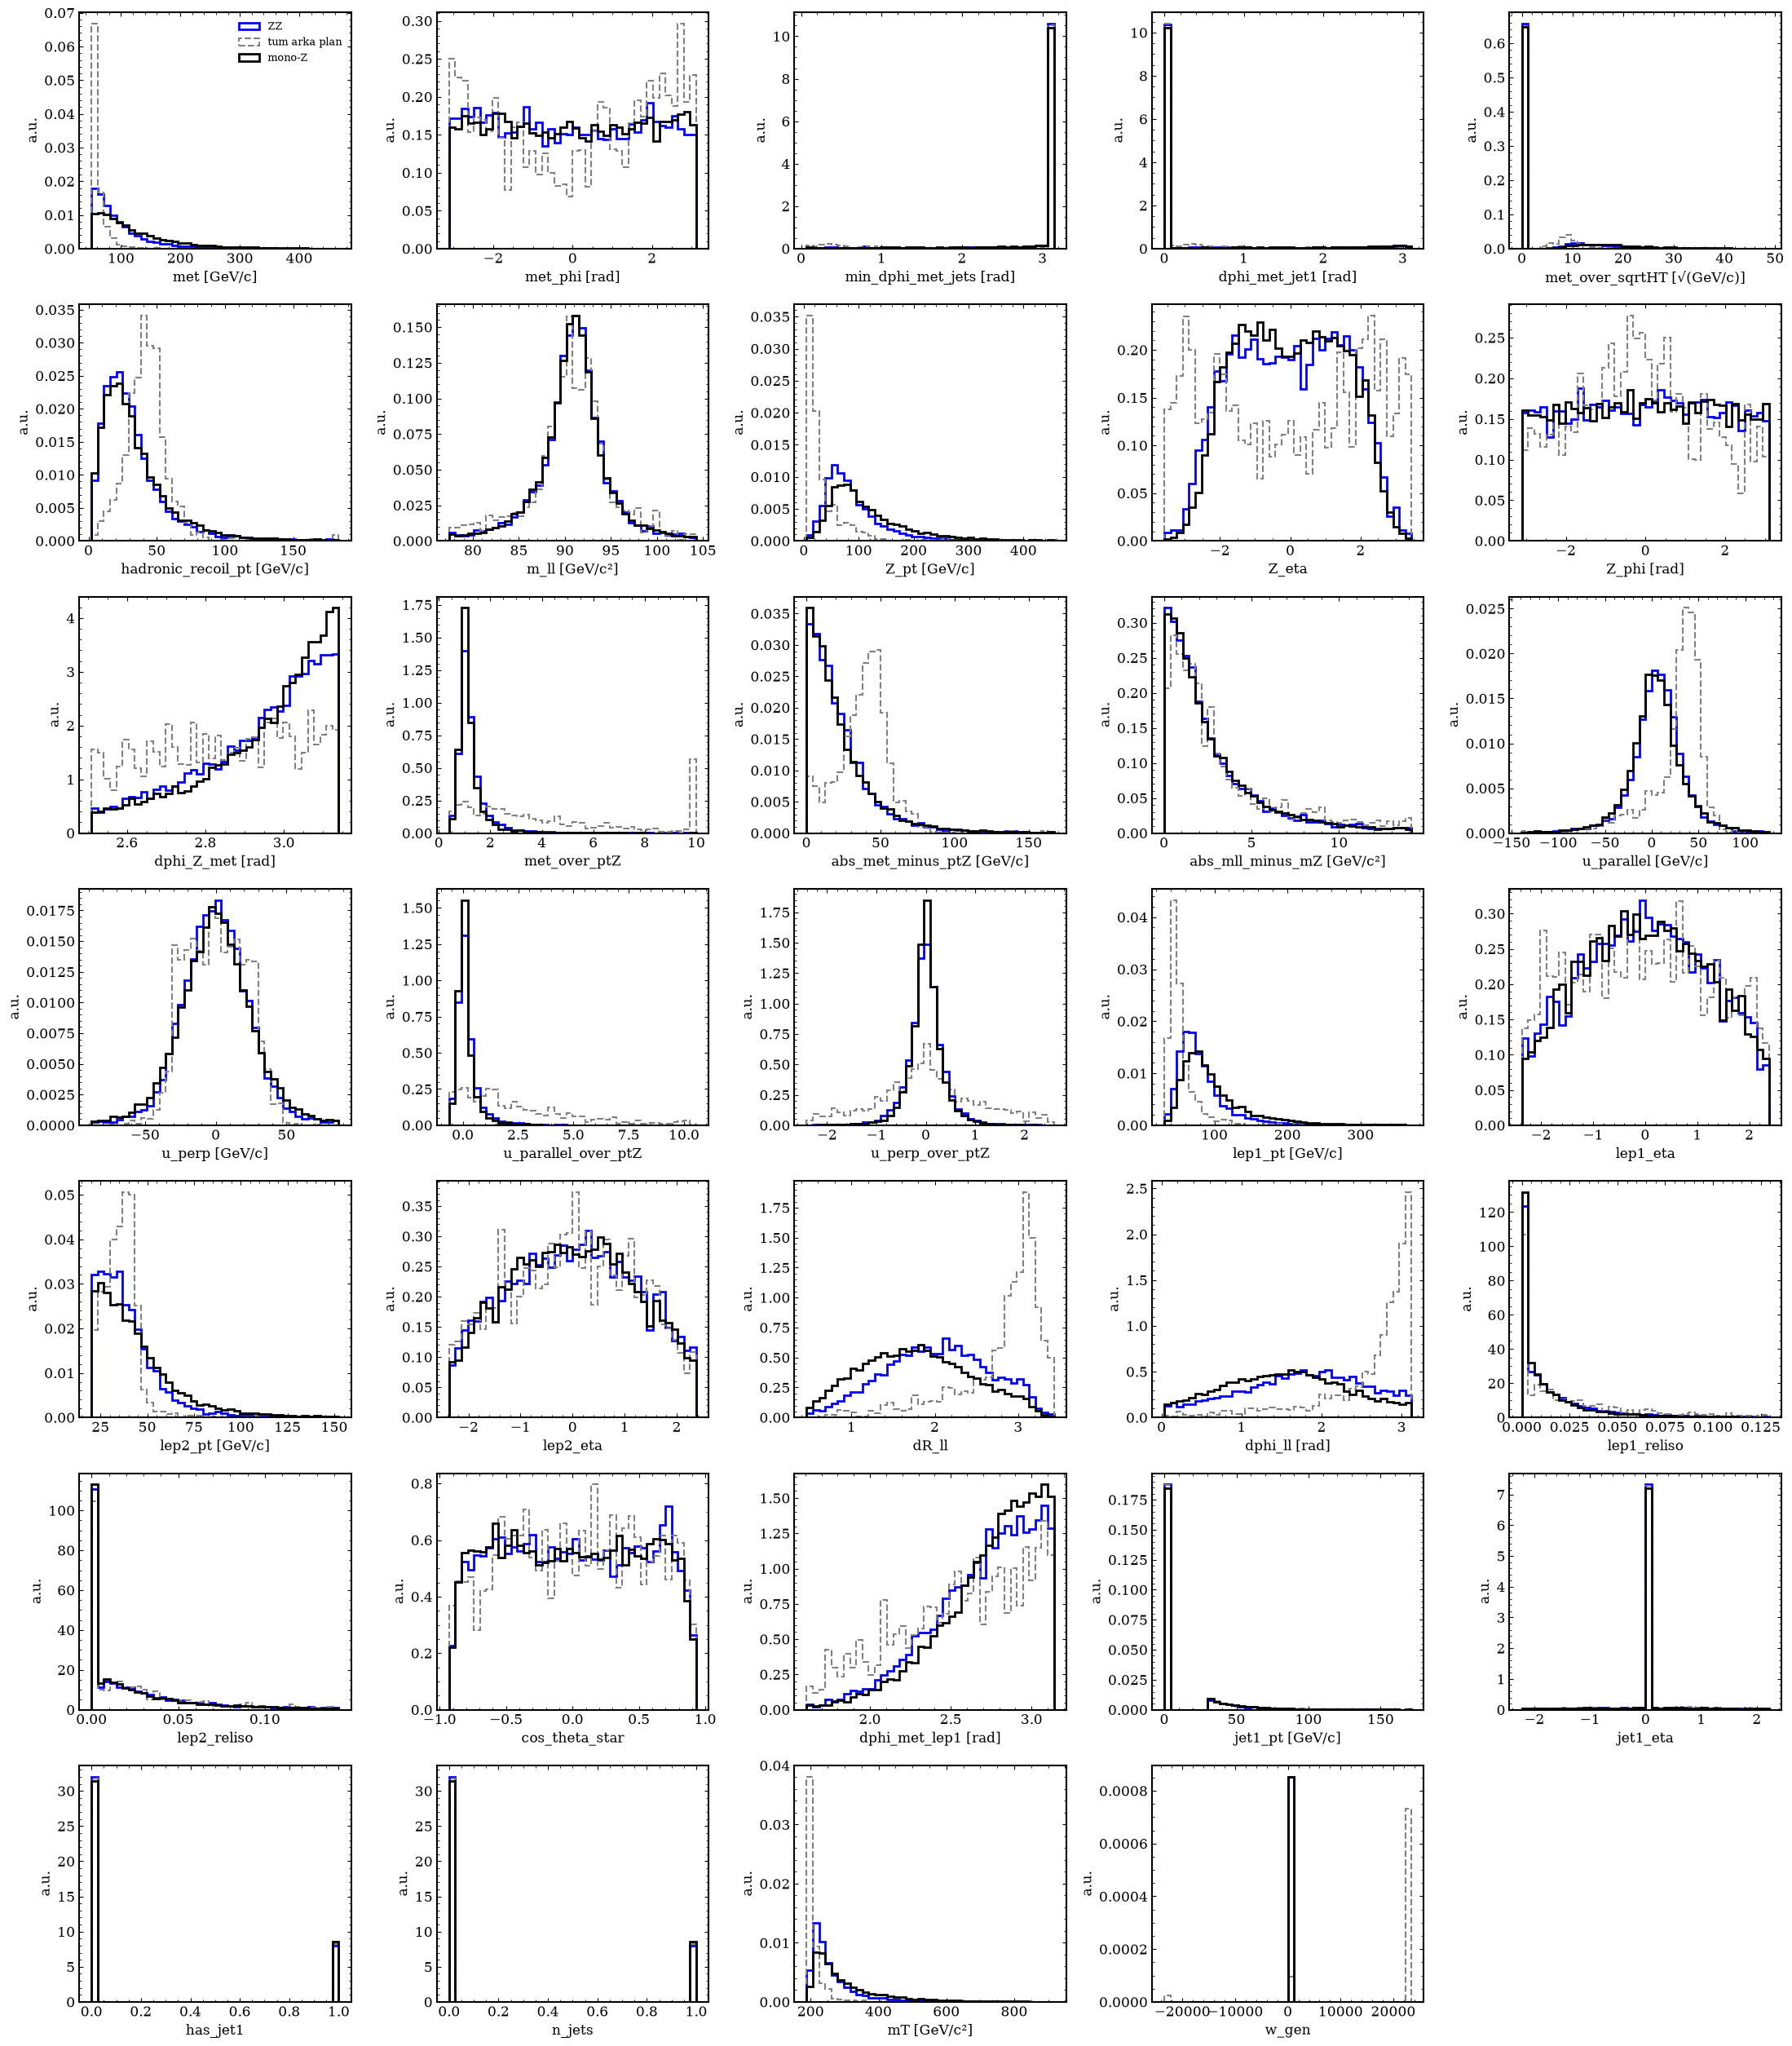

In [50]:
F_kullan = ozet.index[ozet.tur != 'SABIT (at)'].tolist()
zz_sr = bkg[bkg.src == 'ZZ']

n_sutun = 5
n_satir = int(np.ceil(len(F_kullan) / n_sutun))
fig, ax = plt.subplots(n_satir, n_sutun, figsize=(4.4 * n_sutun, 3.6 * n_satir))

for a, f in zip(ax.flat, F_kullan):
    kenar = np.linspace(*np.percentile(pd.concat([bkg[f], sig[f]]), [0.5, 99.5]), 41)
    a.hist(zz_sr[f], bins=kenar, density=True, histtype='step', lw=2,
           color='blue', label='ZZ')
    a.hist(bkg[f], bins=kenar, weights=bkg.weight, density=True,
           histtype='step', lw=1.5, ls='--', color='gray', label='tum arka plan')
    a.hist(sig[f], bins=kenar, density=True, histtype='step', lw=2,
           color='black', label='mono-Z')
    a.set_xlabel(f'{f} [{BIRIM[f]}]' if f in BIRIM else f)
    a.set_ylabel('a.u.')

ax.flat[0].legend(fontsize=9, frameon=False)
for a in ax.flat[len(F_kullan):]:
    a.axis('off')
plt.tight_layout()
plt.show()

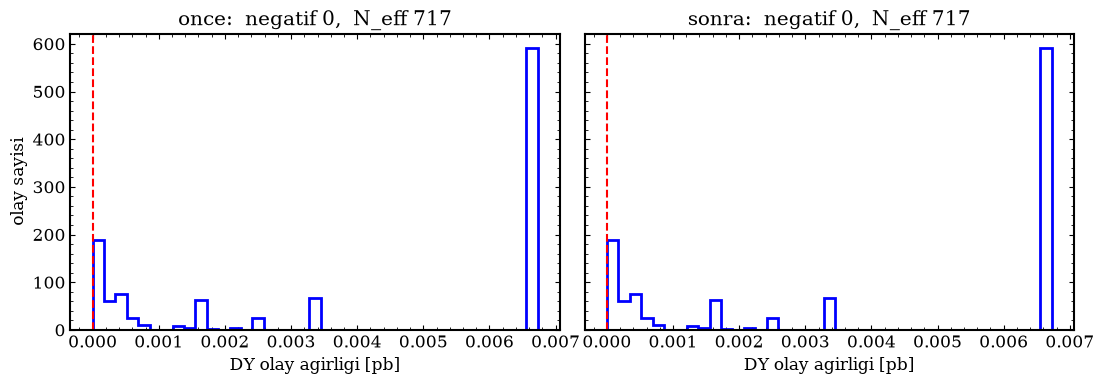

## 1a-2. Yeniden örnekleme: öncesi/sonrası

Hücre yeniden örneklemenin DY ağırlık dağılımı üzerindeki etkisi, uygulamadan hemen önceki ve sonraki hâl yan yana gösterilerek doğrulanır: negatif ağırlıklı olaylar kayboluyor, dağılımın gövdesi aynı kalıyor. Korunan, tüm arka planın toplam ağırlığıdır; hücreler süreçleri karıştırdığı için DY'nin payı komşu $ZZ$/$WZ$ olaylarına kısmen kayar.

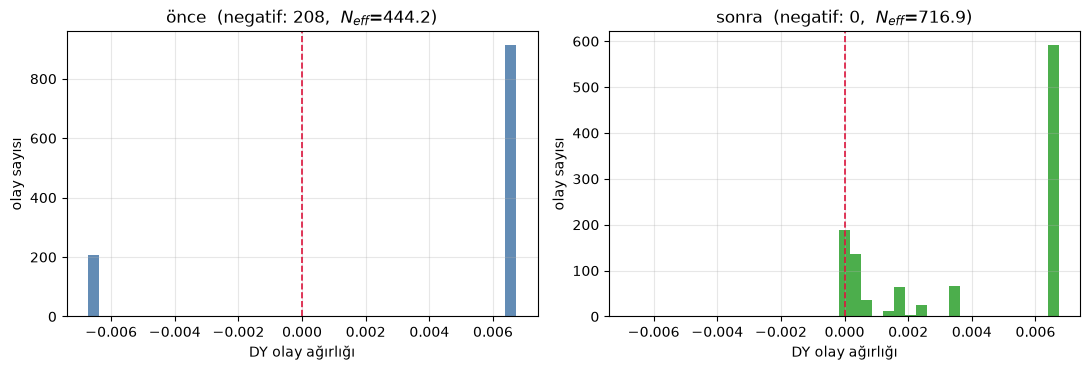

tum arka plan toplam agirlik: 5.0452 -> 5.0452  (korunur)
yalniz DY: 4.7488 -> 4.4761  (surecler arasi kayma)


In [2]:
import matplotlib.pyplot as plt

_ne = lambda w: w.sum()**2 / (w**2).sum() if (w**2).sum() > 0 else 0.
_dy = (bkg.src.to_numpy() == 'DY')
_w1 = bkg.weight.to_numpy()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
lo, hi = np.percentile(_w_once[_dy], [1, 99])
bins = np.linspace(lo, hi, 40)
ax[0].hist(_w_once[_dy], bins=bins, color='#4878a8', alpha=.85)
ax[0].axvline(0, color='crimson', lw=1.2, ls='--')
ax[0].set_title(f'önce  (negatif: {(_w_once[_dy] < 0).sum()},  '
                f'$N_{{eff}}$={_ne(_w_once[_dy]):.1f})')
ax[1].hist(_w1[_dy], bins=bins, color='#2ca02c', alpha=.85)
ax[1].axvline(0, color='crimson', lw=1.2, ls='--')
ax[1].set_title(f'sonra  (negatif: {(_w1[_dy] < 0).sum()},  '
                f'$N_{{eff}}$={_ne(_w1[_dy]):.1f})')
for a in ax:
    a.set_xlabel('DY olay ağırlığı')
    a.set_ylabel('olay sayısı')
    a.grid(alpha=.3)
plt.tight_layout()
plt.show()
# Hucreler surecleri karistirir: DY'nin negatif agirligi komsu
# ZZ/WZ olaylariyla eritilir. Korunan, TUM arka planin toplamidir.
print(f'tum arka plan toplam agirlik: {_w_once.sum():.4f} -> '
      f'{_w1.sum():.4f}  (korunur)')
print(f'yalniz DY: {_w_once[_dy].sum():.4f} -> {_w1[_dy].sum():.4f}'
      '  (surecler arasi kayma)')


## 1b. Öznitelik seçimi

Sekiz değişken literatürdeki yaygınlığa göre önceden seçilmiştir; model
en-iyi-sonucuna göre test kümesinden seçim yapılmamıştır (bu, sızıntı
olurdu). Her değişken en az iki bağımsız kaynakta geçer:

| Değişken | Gerekçe | Kaynak |
| --- | --- | --- |
| $E_T^{\rm miss}$ | Mono-$X$ imzasının tanımlayıcı değişkeni | Bell ve ark. (2012); CMS JHEP **03** (2017) 061 |
| $m_T$ | $ZZ\to2\ell2\nu$ için Jacobi kenarı oluşturur, sinyalde oluşmaz | CMS JHEP **03** (2017) 061 |
| $p_T^{Z}$ | Abdallah ve ark. BDT sıralamasında 2. | Abdallah ve ark. (2019), Tablo II |
| $\Delta\phi(Z,E_T^{\rm miss})$ | Sinyalde sırt sırta topoloji | CMS JHEP **03** (2017) 061; Rasineni & Chebrolu |
| $\Delta R(\ell,\ell)$ | Açık kesim; BDT sıralamasında 3. | Bell ve ark. (2012); Abdallah ve ark. (2019) |
| $m_{\ell\ell}$ | $Z$ kütle penceresi | CMS; Rasineni & Chebrolu, Tablo 1 |
| $n_{\rm jet}$ | Jet vetosu ile $t\bar t$/$tW$ bastırma | CMS; Rasineni & Chebrolu |
| $E_T^{\rm miss}/p_T^{Z}$ | Denge değişkeni, sahte $E_T^{\rm miss}$'i bastırır | CMS; Rasineni & Chebrolu, Tablo 8 |

Aşağıdaki korelasyon matrisi ve tek-değişken AUC'si, bu sekizlinin arka
planla nasıl ilişkili olduğunu ve sinyali ne ölçüde ayırdığını gösterir
(ağırlıklı, SR kesimli).

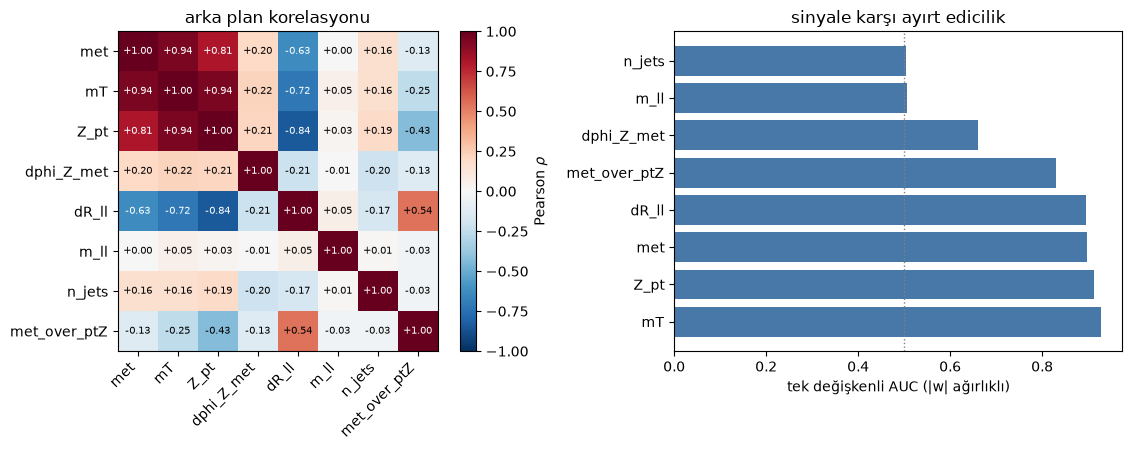

en güçlü 3: mT=0.928, Z_pt=0.912, met=0.898


In [3]:


C = bkg[FEATURES].corr()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
im = ax[0].imshow(C, cmap='RdBu_r', vmin=-1, vmax=1)
ax[0].set_xticks(range(len(FEATURES)))
ax[0].set_xticklabels(FEATURES, rotation=45, ha='right')
ax[0].set_yticks(range(len(FEATURES)))
ax[0].set_yticklabels(FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        col = 'white' if abs(C.iloc[i, j]) > .6 else 'black'
        ax[0].text(j, i, f'{C.iloc[i, j]:+.2f}', ha='center', va='center',
                   fontsize=7, color=col)
fig.colorbar(im, ax=ax[0], label=r'Pearson $\rho$', fraction=0.046)
ax[0].set_title('arka plan korelasyonu')

y = np.r_[np.zeros(len(bkg)), np.ones(len(sig))]
w = np.abs(np.r_[bkg.weight.to_numpy(), sig.weight.to_numpy()])
auc_f = {f: max(a, 1 - a) for f in FEATURES
         for a in [roc_auc_score(y, np.r_[bkg[f], sig[f]], sample_weight=w)]}
order = sorted(auc_f, key=lambda f: -auc_f[f])
ax[1].barh(order, [auc_f[f] for f in order], color='#4878a8')
ax[1].axvline(0.5, color='gray', ls=':', lw=1)
ax[1].set_xlabel('tek değişkenli AUC (|w| ağırlıklı)')
ax[1].set_title('sinyale karşı ayırt edicilik')
plt.tight_layout()
plt.show()
print('en güçlü 3:', ', '.join(f'{f}={auc_f[f]:.3f}' for f in order[:3]))


## 2. Değerlendirme ölçütleri

**Terim ayrımı.** Türkçede iki ayrı nicelik için de "verim" kullanılabildiğinden
bu defterde ikisi ayrılır:

| terim | İngilizce | tanım |
| --- | --- | --- |
| **verim** | *yield* | $\sigma\mathcal{L}$ ile normalize edilmiş beklenen olay sayısı ($S$, $B$) |
| **verimlilik** | *efficiency* | bir kesmeden geçen olay oranı ($\varepsilon_S$, $\varepsilon_B$) |


**İki ayrı ROC hesaplanır ve ikisi de raporlanır.**

*Ham (ağırlıksız) ROC* her olayı eşit sayar; saf makine öğrenmesi ayırma
gücüdür. *Verim ağırlıklı ROC* ise olayları fiziksel ağırlıklarıyla sayar,
yani arka planın gerçek bileşimini yansıtır.

Bu kanalda ikisi **çok farklıdır** ve fark bir kusur değil, ölçülen bir
olgudur: sinyal bölgesinde arka plan olaylarının $\%77$'si $ZZ$'dir, ama $ZZ$
toplam verimin yalnızca $\%1.2$'sini oluşturur; DY ise olayların $\%4.8$'i
olmasına karşın verimin $\%94.5$'idir. Dolayısıyla ağırlıksız AUC fiilen
$ZZ$'ye karşı başarıyı ölçer -- ki $ZZ\to\ell\ell\nu\nu$ sinyalle
kinematik olarak neredeyse özdeş, **indirgenemez** bir arka plandır.

Her iki ROC'tan türetilen anlamlılık iyileştirme eğrisi:

$$\mathrm{SIC}(t)=\frac{\varepsilon_S(t)}{\sqrt{\varepsilon_B(t)}}$$

**Fizik düzeyi.** Asimov anlamlılığı, kesit ve ışınlılıkla normalize edilmiş
verimler üzerinden:

$$Z_A=\sqrt{2\left[(S+B)\ln\!\left(1+\frac{S}{B}\right)-S\right]}$$

İki biçimde raporlanır:

1. **Tek kesim.** Doğrulama kümesinde seçilen tek bir eşiğin üstündeki
   $S$ ve $B$. Basit ama eşiğin üstündeki her şeyi tek sayıya indirger,
   yani dağılımın *şeklini* atar.
2. **Binlenmiş şekil uyumu.** Skor ekseni bölünür ve bin başına
   anlamlılıklar birleştirilir:

$$Z_{\rm şekil}=\sqrt{\textstyle\sum_i Z_{A,i}^2}
\;\xrightarrow[\;S\ll B\;]{}\;
\sqrt{\textstyle\sum_i S_i^2/B_i}$$

Bu, binlenmiş Poisson olabilirliğinin asimptotik karşılığıdır ve HEP'te
standart olan şekil uyumuna denk gelir. Tanım gereği tek kesimden küçük
olamaz. Bin kenarları da **doğrulama** kümesinde belirlenir ve her bin
$N_{\rm eff}\ge10$ etkin arka plan olayı taşır, yani hiçbir bin birkaç
ağır olaya dayanmaz. Sistematik yok, binler bağımsız varsayılır.

**Negatif ağırlıklar.** DY `amcatnloFXFX` ile üretildiği için olayların
$\%16.5$'i negatif üretici ağırlığı taşır ve negatif kütle geçerli bir
olasılık ölçüsü tanımlamaz. Ağırlıklar mutlak değere çevrilmez; bunun yerine
hücre yeniden örneklemesi uygulanır: negatif ağırlıklı her olay, faz
uzayındaki komşularıyla toplamı pozitif olana dek bir hücre oluşturur ve
ağırlık hücre içinde eşit paylaştırılır. Ölçüldü: SR'de negatif ağırlıklı
olay $76 \to 0$, toplam ağırlık **tam korunur** $(5.4119 \to 5.4119)$. Bu
nedenle verim ağırlıklı ROC burada **tanımlıdır**.

Arka plan verimi istatistiksel olarak anlamsız hâle gelmesin diye her çalışma
noktasında Kish etkin örneklem büyüklüğü sınırlanır:

$$N_{\rm eff}=\frac{\left(\sum_i w_i\right)^2}{\sum_i w_i^2}\ \ge\ 10$$

*Kaynak:* G. Cowan ve ark., Eur. Phys. J. C **71** (2011) 1554 (denk. 97);
L. Kish, *Survey Sampling* (1965); S. Andersen, D. Maître, Eur. Phys. J. C
**82** (2022) 433.


In [4]:
NEFF_MIN = 10.0
GRID = np.logspace(-4, 0, 300)      # ortak yanlis pozitif orani izgarasi


def n_eff(weights):
    """Kish etkin orneklem buyuklugu."""
    sq = (weights ** 2).sum()
    return weights.sum() ** 2 / sq if sq > 0 else 0.0


def asimov(s, b):
    """Asimov anlamliligi; tanimsiz bolgede sifir."""
    if s <= 0 or b <= 0:
        return 0.0
    return np.sqrt(2 * ((s + b) * np.log1p(s / b) - s))


def pick_cut(score_bkg, score_sig, w_bkg, w_sig, scale):
    """DOGRULAMA kumesinde Z_A'yi maksimize eden esigi secer.

    Esik yalnizca burada belirlenir. Test kumesi hicbir asamada
    optimizasyona girmez, yalnizca secilmis esikte raporlanir.
    """
    cut, best = np.nan, np.nan
    for t in np.quantile(score_bkg, np.linspace(0.5, 0.9995, 80)):
        w_sel = w_bkg[score_bkg > t]
        b = w_sel.sum() * LUMI * scale
        s = w_sig[score_sig > t].sum() * LUMI * scale
        if s <= 0 or b <= 0 or n_eff(w_sel) < NEFF_MIN:
            continue
        z = asimov(s, b)
        if np.isnan(best) or z > best:
            cut, best = t, z
    return cut


def apply_cut(cut, score_bkg, score_sig, w_bkg, w_sig, scale):
    """Sabit esikte TEST kumesindeki verimler ve anlamlilik."""
    bos = dict(S=np.nan, B=np.nan, Neff=np.nan, epsS=np.nan, epsB=np.nan)
    if np.isnan(cut):
        return bos, np.nan
    kb, ks = score_bkg > cut, score_sig > cut
    w_sel = w_bkg[kb]
    b = w_sel.sum() * LUMI * scale
    s = w_sig[ks].sum() * LUMI * scale
    ne = n_eff(w_sel)
    out = dict(S=s, B=b, Neff=ne, epsS=ks.mean(), epsB=kb.mean())
    return out, (asimov(s, b) if ne >= NEFF_MIN else np.nan)


def shape_edges(score_bkg, w_bkg, neff_min=NEFF_MIN, max_bins=20):
    """Sekil uyumu icin YUKARIDAN ASAGIYA bin kenarlari.

    neff_bins (cizim icin yazilmisti) dusuk uctan baslar ve max_bins'e
    ulasinca kalan butun yuksek-skor bolgesini TEK bine yigar -- oysa
    ayrim tam orada kurulur. Olculdu: boyle kurulan ust bin optimum
    kesimin cok altindan basliyor (0.015 vs 0.163) ve sinyali arka planla
    seyreltiyordu. Burada tersi yapilir: en yuksek skordan asagi inilir,
    her bin N_eff >= neff_min olunca kapanir, yani sinyal bolgesi ince
    binlenir ve kaba binler sadece bos kuyrukta kalir.
    """
    o = np.argsort(score_bkg)[::-1]
    xs, ws = np.asarray(score_bkg)[o], np.asarray(w_bkg)[o]
    ust = xs[0] + abs(xs[0]) * 1e-9 + 1e-9
    kenar, bas = [ust], 0
    for i in range(1, len(xs) + 1):
        p = ws[bas:i]
        q = (p ** 2).sum()
        if q > 0 and p.sum() ** 2 / q >= neff_min and len(kenar) < max_bins:
            kenar.append(xs[i - 1])
            bas = i
    kenar.append(xs[-1] - abs(xs[-1]) * 1e-9 - 1e-9)
    return np.array(kenar[::-1])


def binned_asimov(edges, score_bkg, score_sig, w_bkg, w_sig, scale):
    """Binlenmis sekil uyumu:  Z = sqrt( sum_i Z_i^2 ).

    Tek bir kesim, esigin ustundeki butun olaylari tek bir sayiya indirger
    ve dagilimin SEKLINI atar. Binlenmis Poisson olabilirliginin asimptotik
    karsiligi, bin basina Asimov anlamliliklarinin kareler toplamidir;
    S << B limitinde sum_i S_i^2 / B_i olur (Cowan ve ark. 2011).

    Kenarlar DOGRULAMA kumesinde her bin N_eff ~ NEFF_MIN olacak sekilde
    kuruldugu icin, bagimsiz TEST kumesinde binlerin bir kismi esigin
    altina duser. Bunlari ATMAK sinyali de atar ve sekil uyumunu tek
    kesimin ALTINA dusurur; bu yuzden yetersiz binler yuksek skordan
    baslayarak komsusuyla BIRLESTIRILIR. Birlestirme limitte tek kesime
    indirgenir, dolayisiyla sonuc kesimden kotu olamaz.
    """
    ib = np.clip(np.digitize(score_bkg, edges) - 1, 0, len(edges) - 2)
    isg = np.clip(np.digitize(score_sig, edges) - 1, 0, len(edges) - 2)
    gruplar, birikim = [], []
    for k in range(len(edges) - 2, -1, -1):      # yuksek skordan asagiya
        birikim.append(k)
        wb = w_bkg[np.isin(ib, birikim)]
        if wb.sum() > 0 and n_eff(wb) >= NEFF_MIN:
            gruplar.append(list(birikim))
            birikim = []
    if birikim and gruplar:
        gruplar[-1].extend(birikim)              # artani son gruba kat
    z2 = 0.0
    for g in gruplar:
        wb = w_bkg[np.isin(ib, g)]
        b = wb.sum() * LUMI * scale
        s = w_sig[np.isin(isg, g)].sum() * LUMI * scale
        if s <= 0 or b <= 0 or n_eff(wb) < NEFF_MIN:
            continue
        z2 += asimov(s, b) ** 2
    return np.sqrt(z2)


def roc_on_grid(score_bkg, score_sig, w_bkg=None, w_sig=None):
    """ROC'u ortak izgaraya tasir; (eps_S, SIC) dondurur.

    Agirlik verilirse verim-agirlikli ROC hesaplanir. Hucre yeniden
    ornekleme sonrasi tum agirliklar negatif olmadigindan bu gecerlidir.
    """
    truth = np.r_[np.zeros(len(score_bkg)), np.ones(len(score_sig))]
    sw = None if w_bkg is None else np.r_[w_bkg, w_sig]
    fpr, tpr, _ = roc_curve(truth, np.r_[score_bkg, score_sig],
                            sample_weight=sw)
    eps_s = np.interp(GRID, fpr, tpr)
    return eps_s, eps_s / np.sqrt(GRID)

## 3. Üç model

Hiperparametreler bilinçli olarak sade ve literatürdeki temel kurulumlarla
uyumludur; amaç en iyi ayarı aramak değil, üç yaklaşımı eşit koşulda
karşılaştırmaktır. Kapsamlı hiperparametre taraması yapılmamıştır.

**BDT.** Gradyan artırmalı karar ağaçları, HEP'te TMVA ve XGBoost ile kurulan
standart kurulumdur. Burada `HistGradientBoostingClassifier` kullanılır: aynı
histogram tabanlı gradyan artırma algoritması (LightGBM soyundan), ek bağımlılık
gerektirmez. Ağaç toplulukları gradyan tabanlı sinir ağları olmadığından torch
ile kurulmaz; bu, literatürdeki yerleşik uygulamanın gereğidir.

**DNN.** PyTorch ile iki gizli katmanlı (128 birim, ReLU, dropout 0.1) tam
bağlı sınıflandırıcı; `BCEWithLogitsLoss`, Adam, erken durdurma. Çıktı
$\tanh(z/2)=2\hat p-1$ olarak verilir; bu, log-oranın tek-yönlü monoton bir
dönüşümüdür, dolayısıyla sıralama olabilirlik oranının sıralamasıdır.

**NSF.** Rasyonel kuadratik spline akışları (`zuko.flows.NSF`, 8 dönüşüm,
8 bin, 256$\times$2 bağlam ağı). İki ayrı yoğunluk öğrenilir ve skor
$\log p(x\mid S)-\log p(x\mid B)$ olarak kurulur. Ayrık `n_jets` değişkeni
eğitimde dequantize edilir ($x\to x+u$, $u\sim U[-\tfrac12,\tfrac12]$); aksi
halde sürekli yoğunluk ayrık noktalarda ıraksar. Jacobian katkıları zuko'nun
`log_prob` çağrısında tam olarak hesaba katılır.

Her model aynı `StandardScaler` ile ölçeklenir ve ölçekleyici **yalnızca eğitim
kümesinde** uydurulur.

*Kaynak:* T. Chen, C. Guestrin, KDD '16, 785 (XGBoost); C. Durkan ve ark.,
NeurIPS **32** (2019) 7511 (Neural Spline Flows); A. Rogozhnikov ve ark.
(HEP'te BDT uygulamalari).

In [5]:
def fit_bdt(x_tr, y_tr, w_tr, x_va, y_va, w_va, seed,
            step=25, max_iter=600, patience=4):
    """Gradyan artirmali agaclar; agac sayisi DOGRULAMA kaybiyla secilir.

    sklearn'un kendi erken durdurmasi egitim kumesinden rastgele bir dilim
    ayirir; burada bunun yerine acikca ayrilmis dogrulama kumesi kullanilir,
    boylece uc model de ayni kumede durdurulur.
    """
    probe = HistGradientBoostingClassifier(
        max_depth=4, learning_rate=0.08, early_stopping=False,
        warm_start=True, max_iter=step, random_state=seed)
    best, best_n, waited = np.inf, step, 0
    for n in range(step, max_iter + 1, step):
        probe.max_iter = n
        probe.fit(x_tr, y_tr, sample_weight=w_tr)
        loss = log_loss(y_va, probe.predict_proba(x_va)[:, 1],
                        sample_weight=w_va)
        if loss < best - 1e-5:
            best, best_n, waited = loss, n, 0
        else:
            waited += 1
            if waited >= patience:
                break
    model = HistGradientBoostingClassifier(
        max_depth=4, learning_rate=0.08, early_stopping=False,
        max_iter=best_n, random_state=seed)
    model.fit(x_tr, y_tr, sample_weight=w_tr)
    return (lambda x: 2 * model.predict_proba(x)[:, 1] - 1), best_n


class Mlp(nn.Module):
    """Iki gizli katmanli sinif olasiligi kestiricisi."""

    def __init__(self, n_features, width=128, p_drop=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, width), nn.ReLU(), nn.Dropout(p_drop),
            nn.Linear(width, width), nn.ReLU(), nn.Dropout(p_drop),
            nn.Linear(width, 1))

    def forward(self, x):
        return self.net(x).squeeze(-1)


def fit_dnn(x_tr, y_tr, w_tr, x_va, y_va, w_va, seed,
            epochs=200, patience=20):
    """Capraz entropi ile egitilen MLP; durdurma dogrulama kumesinde."""
    torch.manual_seed(seed)
    tt = lambda a: torch.tensor(a, dtype=torch.float32, device=DEVICE)
    x, y, w = tt(x_tr), tt(y_tr), tt(w_tr)
    xv, yv, wv = tt(x_va), tt(y_va), tt(w_va)
    model = Mlp(x.shape[1]).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    loss_fn = nn.BCEWithLogitsLoss(reduction='none')
    best_loss, best_state, waited = np.inf, None, 0
    for _ in range(epochs):
        model.train()
        perm = torch.randperm(len(x), device=DEVICE)
        for i in range(0, len(perm), 1024):
            j = perm[i:i + 1024]
            loss = (loss_fn(model(x[j]), y[j]) * w[j]).sum() / w[j].sum()
            opt.zero_grad()
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            v = ((loss_fn(model(xv), yv) * wv).sum() / wv.sum()).item()
        if v < best_loss:
            best_loss, waited = v, 0
            best_state = {k: t.clone() for k, t in model.state_dict().items()}
        else:
            waited += 1
            if waited >= patience:
                break
    model.load_state_dict(best_state)
    model.eval()

    @torch.no_grad()
    def score(x_new):
        t = torch.tensor(x_new, dtype=torch.float32, device=DEVICE)
        return torch.tanh(model(t) / 2).cpu().numpy()

    return score


def fit_flow(x_train, x_valid, seed, jet_col=None, epochs=200, patience=20):
    """Tek bir yogunlugu ogrenen rasyonel kuadratik spline akisi."""
    torch.manual_seed(seed)
    flow = zuko.flows.NSF(features=x_train.shape[1], context=0, transforms=8,
                          bins=8, hidden_features=[256, 256]).to(DEVICE)
    opt = torch.optim.Adam(flow.parameters(), lr=3e-4, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs,
                                                       eta_min=1e-6)
    x = torch.tensor(x_train, dtype=torch.float32, device=DEVICE)
    xv = torch.tensor(x_valid, dtype=torch.float32, device=DEVICE)
    best_loss, best_state, waited = np.inf, None, 0
    for _ in range(epochs):
        flow.train()
        perm = torch.randperm(len(x), device=DEVICE)
        for i in range(0, len(perm), 2048):
            batch = x[perm[i:i + 2048]].clone()
            if jet_col is not None:            # ayrik degiskeni dequantize et
                batch[:, jet_col] += torch.rand_like(batch[:, jet_col]) - 0.5
            loss = -flow().log_prob(batch).mean()
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(flow.parameters(), 1.0)
            opt.step()
        sched.step()
        flow.eval()
        with torch.no_grad():
            v = -flow().log_prob(xv).mean().item()
        if v < best_loss:
            best_loss, waited = v, 0
            best_state = {k: t.clone() for k, t in flow.state_dict().items()}
        else:
            waited += 1
            if waited >= patience:
                break
    flow.load_state_dict(best_state)
    flow.eval()
    return flow


@torch.no_grad()
def log_prob(flow, x_new, chunk=8192):
    """Yogunlugu parcalar halinde degerlendirir."""
    t = torch.tensor(x_new, dtype=torch.float32, device=DEVICE)
    return np.concatenate([flow().log_prob(t[i:i + chunk]).cpu().numpy()
                           for i in range(0, len(t), chunk)])

## 4. Adil karşılaştırma protokolü

**Bölünme.** Her tohumda sinyal ve arka plan *ayrı ayrı* %60 eğitim / %20
doğrulama / %20 test olarak bölünür. İki sınıf kendi içinde bölündüğü için
sınıf oranları üç kümede de korunur (stratified split).

**Her kümenin tek bir görevi var:**

| küme | kullanım |
| --- | --- |
| eğitim (%60) | model parametreleri |
| doğrulama (%20) | erken durdurma **ve** $Z_A$ eşiğinin seçimi |
| test (%20) | yalnızca raporlama |

**Sızıntıya karşı iki önlem.** (i) Ölçekleyici yalnızca eğitim kümesinde
uydurulur. (ii) $Z_A$'yı maksimize eden eşik **doğrulama** kümesinde seçilir
ve test kümesinde *sabit* olarak uygulanır. Eşiği doğrudan test kümesinde
aramak, test kümesiyle model seçmek anlamına gelir ve anlamlılığı yukarı
yanlı kestirir.

**Erken durdurma üçünde de aynı kümede.** BDT'de ağaç sayısı doğrulama
log-kaybıyla seçilir (scikit-learn'ün kendi iç bölünmesi devre dışı);
DNN'de doğrulama çapraz entropisi; NSF'de doğrulama negatif
log-olabilirliği izlenir.

**Ağırlıkların ayrımı.** Eğitimde yalnızca sınıf dengeleyici ağırlık
$w_i = \tfrac12/N_{\rm sınıf}$ kullanılır; fiziksel kesit ağırlıkları
*yalnızca* verim ve anlamlılık hesabına girer. İki ağırlık hiçbir yerde
karıştırılmaz.

Beş bağımsız bölünme (tohum 0--4) koşulur; belirsizlikler bu beş ölçümün
standart sapmasıdır.

In [6]:
MODELS = ('BDT', 'DNN', 'NSF')
FRAC = 0.2                      # dogrulama ve test paylari -> 60/20/20


def split3(df, seed):
    """Sinif ici 60/20/20 bolunme (stratified)."""
    tr, rest = train_test_split(df, test_size=2 * FRAC, random_state=seed)
    va, te = train_test_split(rest, test_size=0.5, random_state=seed)
    return tr, va, te


def evaluate_split(seed):
    """Bir bolunmede uc modeli kurar; olcutleri ve egrileri dondurur."""
    b_tr, b_va, b_te = split3(bkg, seed)
    s_tr, s_va, s_te = split3(sig, seed)
    scaler = StandardScaler().fit(b_tr[FEATURES])     # yalnizca egitimde
    tf = lambda d: scaler.transform(d[FEATURES])
    jet_col = FEATURES.index('n_jets')

    def xyw(bd, sd):
        """Sinif dengeli egitim/dogrulama girdisi (fizik agirligi degil)."""
        x = np.vstack([tf(bd), tf(sd)])
        y = np.r_[np.zeros(len(bd)), np.ones(len(sd))]
        w = np.r_[np.full(len(bd), 0.5 / len(bd)),
                  np.full(len(sd), 0.5 / len(sd))]
        return x, y, w

    x_tr, y_tr, w_tr = xyw(b_tr, s_tr)
    x_va, y_va, w_va = xyw(b_va, s_va)

    bdt_score, n_tree = fit_bdt(x_tr, y_tr, w_tr, x_va, y_va, w_va, seed)
    scorers = {'BDT': bdt_score,
               'DNN': fit_dnn(x_tr, y_tr, w_tr, x_va, y_va, w_va, seed)}
    flow_sm = fit_flow(tf(b_tr), tf(b_va), seed, jet_col)
    flow_dm = fit_flow(tf(s_tr), tf(s_va), seed, jet_col)
    scorers['NSF'] = lambda x: log_prob(flow_dm, x) - log_prob(flow_sm, x)

    row, curves = {'seed': seed, 'n_tree_BDT': n_tree}, {}
    wb_va, ws_va = b_va.weight.to_numpy(), s_va.weight.to_numpy()
    wb_te, ws_te = b_te.weight.to_numpy(), s_te.weight.to_numpy()
    for name in MODELS:
        f = scorers[name]
        sb_tr, ss_tr = f(tf(b_tr)), f(tf(s_tr))
        sb_va, ss_va = f(tf(b_va)), f(tf(s_va))
        sb, ss = f(tf(b_te)), f(tf(s_te))

        cut = pick_cut(sb_va, ss_va, wb_va, ws_va, 1 / FRAC)   # dogrulamada
        nokta, za = apply_cut(cut, sb, ss, wb_te, ws_te, 1 / FRAC)  # testte
        # Sekil uyumu: bin kenarlari da dogrulamada belirlenir.
        kenar = shape_edges(sb_va, wb_va, max_bins=20)
        za_bin = binned_asimov(kenar, sb, ss, wb_te, ws_te, 1 / FRAC)

        truth = np.r_[np.zeros(len(sb)), np.ones(len(ss))]
        eps_s, sic = roc_on_grid(sb, ss)
        eps_w, sic_w = roc_on_grid(sb, ss, wb_te, ws_te)
        row[f'auc_{name}'] = roc_auc_score(truth, np.r_[sb, ss])
        row[f'aucw_{name}'] = roc_auc_score(truth, np.r_[sb, ss],
                                            sample_weight=np.r_[wb_te, ws_te])
        row[f'auctr_{name}'] = roc_auc_score(
            np.r_[np.zeros(len(sb_tr)), np.ones(len(ss_tr))],
            np.r_[sb_tr, ss_tr])
        row[f'sic_{name}'] = sic.max()
        row[f'sicw_{name}'] = sic_w.max()
        row[f'rej_{name}'] = 1 / np.interp(0.5, eps_w, GRID)
        row[f'cut_{name}'], row[f'Za_{name}'] = cut, za
        row[f'Zabin_{name}'], row[f'nbin_{name}'] = za_bin, len(kenar) - 1
        for k, v in nokta.items():
            row[f'{k}_{name}'] = v
        curves[name] = {'eps_s': eps_s, 'sic': sic, 'eps_s_w': eps_w,
                        'sic_w': sic_w, 'sb': sb, 'ss': ss, 'cut': cut}
    return row, curves, (wb_te, ws_te, b_te['src'].to_numpy())


rows, curves_all = [], []
for seed in range(5):
    row, curves, test_w = evaluate_split(seed)
    rows.append(row)
    curves_all.append(curves)
    print(f'  tohum {seed} ({row["n_tree_BDT"]:3d} agac): ' + '  '.join(
        f'{m} AUC={row[f"aucw_{m}"]:.3f} Za={row[f"Za_{m}"]:.2f}'
        f'/{row[f"Zabin_{m}"]:.2f}' for m in MODELS), flush=True)

results = pd.DataFrame(rows)
results.to_csv(OUT + 'seed_results.csv', index=False)

  tohum 0 ( 50 agac): BDT AUC=0.964 Za=4.54/4.48  DNN AUC=0.965 Za=4.63/4.92  NSF AUC=0.869 Za=1.76/1.93


  tohum 1 ( 50 agac): BDT AUC=0.955 Za=4.66/4.69  DNN AUC=0.960 Za=4.75/4.83  NSF AUC=0.893 Za=1.90/2.49


  tohum 2 ( 75 agac): BDT AUC=0.963 Za=4.73/4.72  DNN AUC=0.965 Za=4.75/4.87  NSF AUC=0.879 Za=nan/2.62


  tohum 3 ( 25 agac): BDT AUC=0.966 Za=4.62/4.55  DNN AUC=0.965 Za=3.97/4.92  NSF AUC=0.900 Za=1.69/2.59


  tohum 4 ( 50 agac): BDT AUC=0.958 Za=4.18/4.77  DNN AUC=0.959 Za=4.05/4.72  NSF AUC=0.883 Za=2.01/2.36


## 5. Sayısal sonuçlar

Üç ölçüt ayrı şeyler söyler ve bilinçli olarak birlikte raporlanır:

- **AUC (verim)** — fiziksel arka plan karışımında sıralama gücü.
- **AUC (ham)** ve **eğitim$-$test farkı** — saf sınıflandırma başarısı ve
  aşırı öğrenme kontrolü. Fark $\gtrsim 0.02$ ise model eğitim kümesini
  ezberlemeye başlamıştır.
- **$1/\varepsilon_B$** — $\varepsilon_S = 0.5$'te arka plan baskılama.
- **$Z_A$** — doğrulama kümesinde seçilen sabit eşikte, test kümesindeki
  anlamlılık. Öncelik budur: yüksek AUC değil, güvenilir anlamlılık.

In [7]:
summary = pd.DataFrame(
    {'AUC_verim': [results[f'aucw_{m}'].mean() for m in MODELS],
     'AUC_ham': [results[f'auc_{m}'].mean() for m in MODELS],
     'AUC_egitim': [results[f'auctr_{m}'].mean() for m in MODELS],
     'asiri_ogrenme': [(results[f'auctr_{m}'] - results[f'auc_{m}']).mean()
                       for m in MODELS],
     'SIC_verim': [results[f'sicw_{m}'].mean() for m in MODELS],
     'SIC_ham': [results[f'sic_{m}'].mean() for m in MODELS],
     'rej_at_eps_S_0.5': [results[f'rej_{m}'].mean() for m in MODELS],
     'Z_A_kesim': [results[f'Za_{m}'].mean() for m in MODELS],
     'Z_A_kesim_sd': [results[f'Za_{m}'].std() for m in MODELS],
     'Z_A_sekil': [results[f'Zabin_{m}'].mean() for m in MODELS],
     'Z_A_sekil_sd': [results[f'Zabin_{m}'].std() for m in MODELS],
     'n_bin': [results[f'nbin_{m}'].mean() for m in MODELS]},
    index=list(MODELS)).round(3)
summary.to_csv(OUT + 'model_comparison.csv')
print(summary.to_string())
print(f'\nBDT agac sayisi (dogrulamada secildi): '
      f'{results["n_tree_BDT"].tolist()}')
kazanc = [results[f'Zabin_{m}'].mean() / results[f'Za_{m}'].mean()
          for m in MODELS]
print('sekil uyumunun kesime gore kazanci: ' +
      ', '.join(f'{m} {k:.2f}x' for m, k in zip(MODELS, kazanc)))
gecersiz = int(results[[f'Za_{m}' for m in MODELS]].isna().sum().sum())
if gecersiz:
    print(f'uyari: {gecersiz} olcumde N_eff >= {NEFF_MIN:.0f} kosulunu '
          'saglayan calisma noktasi bulunamadi (NaN)')

     AUC_verim  AUC_ham  AUC_egitim  asiri_ogrenme  SIC_verim  SIC_ham  rej_at_eps_S_0.5  Z_A_kesim  Z_A_kesim_sd  Z_A_sekil  Z_A_sekil_sd  n_bin
BDT      0.961    0.680       0.704          0.024      5.748    1.071           103.125      4.546         0.215      4.644         0.123   20.0
DNN      0.963    0.681       0.691          0.010      5.774    1.072           100.694      4.431         0.388      4.855         0.083   20.0
NSF      0.885    0.638       0.683          0.045      2.619    1.027            17.732      1.839         0.143      2.398         0.282   20.0

BDT agac sayisi (dogrulamada secildi): [50, 50, 75, 25, 50]
sekil uyumunun kesime gore kazanci: BDT 1.02x, DNN 1.10x, NSF 1.30x
uyari: 1 olcumde N_eff >= 10 kosulunu saglayan calisma noktasi bulunamadi (NaN)


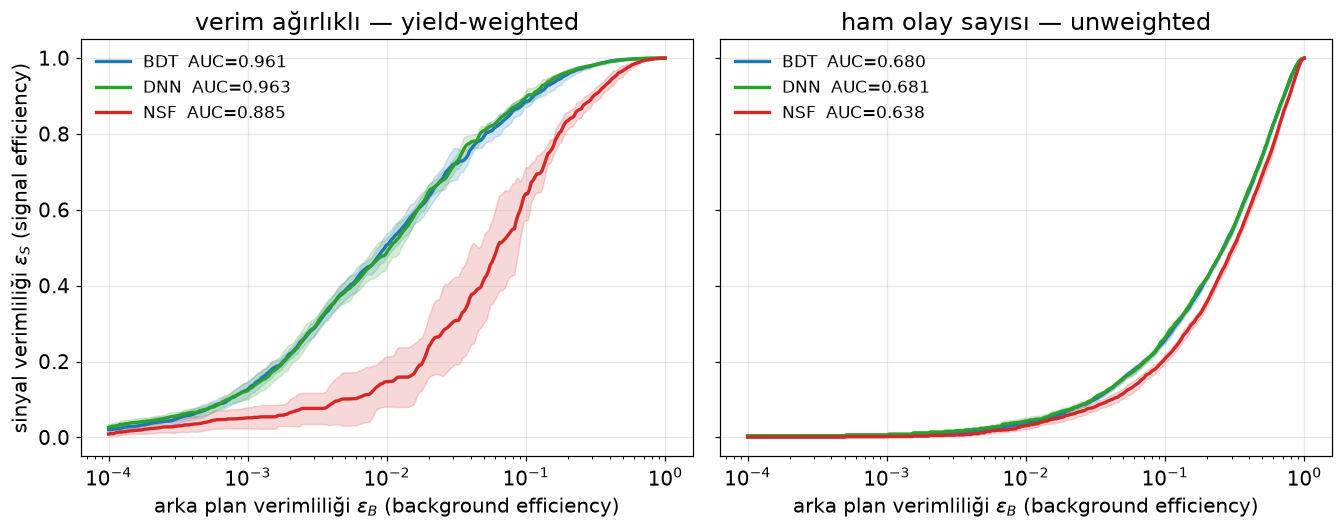

In [8]:
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 13, 'figure.dpi': 110})
COLOR = {'BDT': '#1f77b4', 'DNN': '#2ca02c', 'NSF': '#d62728'}


def band(ax, key, ylabel, etiket):
    """Bes bolunmenin ortalamasi ve +-1 sigma bandi."""
    for m in MODELS:
        y = np.array([c[m][key] for c in curves_all])
        mu, sd = y.mean(0), y.std(0)
        ax.plot(GRID, mu, color=COLOR[m], lw=2.2, label=f'{m}  {etiket(m)}')
        ax.fill_between(GRID, mu - sd, mu + sd, color=COLOR[m], alpha=0.18)
    ax.set_xscale('log')
    ax.set_xlabel(r'arka plan verimliliği $\varepsilon_B$'
                  ' (background efficiency)')
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    ax.legend(frameon=False, fontsize=11)


# Sekil 1 -- ROC: verim agirlikli (fizik) ve ham (saf ML ayirma)
fig, ax = plt.subplots(1, 2, figsize=(12.4, 5), sharey=True)
band(ax[0], 'eps_s_w',
     r'sinyal verimliliği $\varepsilon_S$ (signal efficiency)',
     lambda m: f'AUC={summary.loc[m, "AUC_verim"]:.3f}')
ax[0].set_title('verim ağırlıklı — yield-weighted')
band(ax[1], 'eps_s', '', lambda m: f'AUC={summary.loc[m, "AUC_ham"]:.3f}')
ax[1].set_title('ham olay sayısı — unweighted')
fig.tight_layout()
fig.savefig(OUT + 'roc_comparison.pdf')
plt.show()

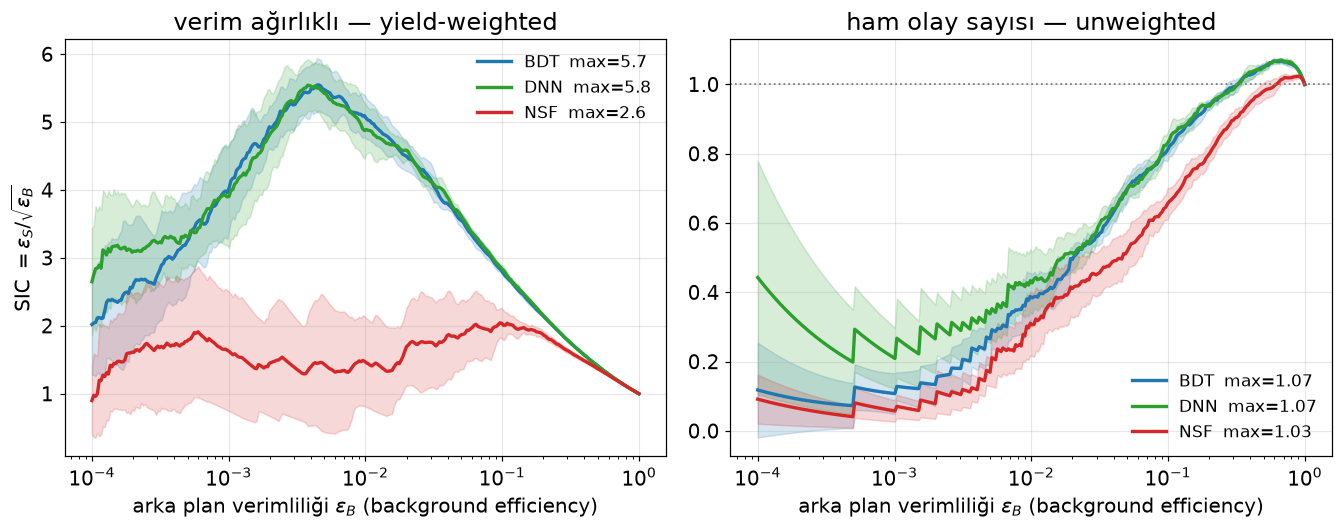

In [9]:
# Sekil 2 -- SIC
fig, ax = plt.subplots(1, 2, figsize=(12.4, 5))
band(ax[0], 'sic_w', r'SIC $=\varepsilon_S/\sqrt{\varepsilon_B}$',
     lambda m: f'max={summary.loc[m, "SIC_verim"]:.1f}')
ax[0].set_title('verim ağırlıklı — yield-weighted')
band(ax[1], 'sic', '',
     lambda m: f'max={summary.loc[m, "SIC_ham"]:.2f}')
ax[1].set_title('ham olay sayısı — unweighted')
ax[1].axhline(1.0, color='gray', ls=':', lw=1.2)
fig.tight_layout()
fig.savefig(OUT + 'sic_comparison.pdf')
plt.show()

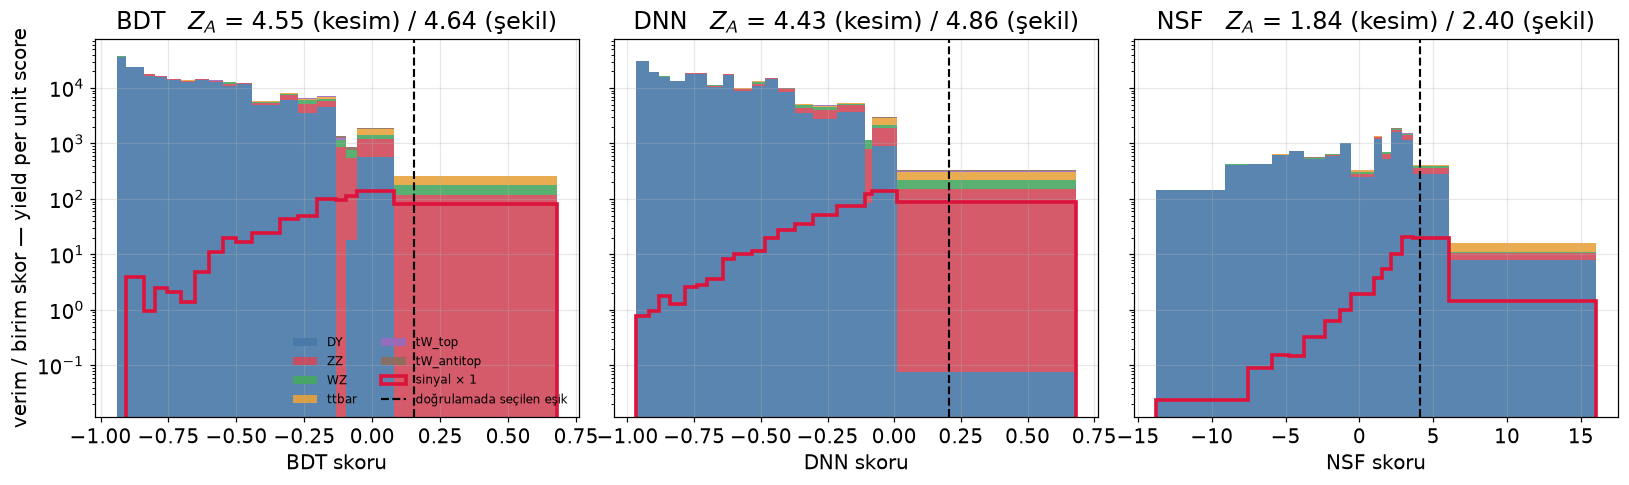

In [10]:
# Sekil 3 -- skor dagilimlari, surec bazinda yiginli
# Degisken genislikli binlerde hist() bin basina TOPLAM cizer; genis bir bin
# otomatik yuksek gorunur. Agirligi bin genisligine bolup birim skor basina
# verim cizilir, boylece binler karsilastirilabilir olur.
def per_width(x, w, edges):
    """Agirligi dustugu binin genisligine boler."""
    i = np.clip(np.digitize(x, edges) - 1, 0, len(edges) - 2)
    return w / np.diff(edges)[i]


def display_bins(x, w, neff_min=10.0, max_bins=25):
    """Gosterim icin N_eff-uyarlamali binleme, TABAN genislikli.

    neff_bins yalnizca etkin olay sayisina bakar; skorun yerel yogun
    oldugu bir bolgede (ornegin karar esigine yakin) birkac agir DY
    olayi birbirine cok yakin dusup kilcal genislikte bir bin olusturabilir.
    Toplam agirlik kucuk olsa da "birim skor basina verim" bu dar bine
    bolununce yapay bir sivri uc ortaya cikar -- istatistiksel olarak
    gecerli ama gorsel olarak yaniltici. Taban genislik bunu onler.
    """
    edges = neff_bins(x, w, neff_min=neff_min, max_bins=max_bins)
    floor = (x.max() - x.min()) / max_bins / 2.5
    k = [edges[0]]
    for e in edges[1:]:
        if e - k[-1] >= floor or e == edges[-1]:
            k.append(e)
    return np.array(k)


PROC = ['DY', 'ZZ', 'WZ', 'ttbar', 'tW_top', 'tW_antitop']
PROC_RENK = ['#4878a8', '#d1495b', '#48a860', '#e8a33d', '#9b6bbf', '#8c6d5c']
w_b, w_s, src_b = test_w
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, m in zip(axes, MODELS):
    c = curves_all[-1][m]
    sb, ss = c['sb'], c['ss']
    edges = display_bins(sb, w_b, neff_min=10.0, max_bins=25)
    ax.hist([sb[src_b == p] for p in PROC], bins=edges, stacked=True,
            color=PROC_RENK, label=PROC, alpha=0.9,
            weights=[per_width(sb[src_b == p], w_b[src_b == p] * LUMI / FRAC,
                               edges) for p in PROC])
    ax.hist(ss, bins=edges, histtype='step', color='crimson', lw=2.4,
            weights=per_width(ss, w_s * LUMI / FRAC, edges),
            label=r'sinyal $\times$ 1')
    ax.axvline(c['cut'], color='k', ls='--', lw=1.4,
               label='doğrulamada seçilen eşik')
    ax.set_yscale('log')
    ax.set_xlabel(f'{m} skoru')
    ax.set_title(f'{m}   $Z_A$ = {summary.loc[m, "Z_A_kesim"]:.2f}'
                 f' (kesim) / {summary.loc[m, "Z_A_sekil"]:.2f} (şekil)')
    ax.grid(alpha=0.3)
axes[0].set_ylabel(r'verim / birim skor — yield per unit score')
axes[0].legend(fontsize=8, ncol=2, frameon=False)
fig.tight_layout()
fig.savefig(OUT + 'score_distributions.pdf')
plt.show()

## 5c. Ağırlıksız AUC neden düşük görünüyor?

Toplam ağırlıksız AUC (BDT $\approx0.68$), arka planı oluşturan süreçlerin olay-sayısı ağırlıklı ortalamasıdır. Son bölünmenin BDT skorları, test kümesindeki her sürece ayrı ayrı uygulanarak bu toplamın nereden geldiği gösterilir.

In [11]:
w_b, w_s, src_b = test_w
sb_last = curves_all[-1]['BDT']['sb']
ss_last = curves_all[-1]['BDT']['ss']
yt_last = np.r_[np.zeros(len(sb_last)), np.ones(len(ss_last))]

bilesen = []
for p in sorted(set(src_b)):
    m = src_b == p
    if m.sum() < 30:
        continue
    y_p = np.r_[np.zeros(m.sum()), np.ones(len(ss_last))]
    auc_p = roc_auc_score(y_p, np.r_[sb_last[m], ss_last])
    bilesen.append({'surec': p, 'olay_payi': m.mean(), 'auc': auc_p})
bilesen = pd.DataFrame(bilesen).sort_values('olay_payi', ascending=False)
bilesen.to_csv(OUT + 'bilesen_auc.csv', index=False)
print(bilesen.round(3).to_string(index=False))


surec  olay_payi   auc
   ZZ      0.709 0.620
   WZ      0.161 0.727
   DY      0.108 0.969


## 5b. Çalışma noktası ve karışıklık matrisi

Her model, **doğrulama kümesinde** seçilmiş kendi eşiğinde değerlendirilir;
aşağıdaki sayıların tamamı **test kümesinden** gelir. Karışıklık matrisi ham
olay sayılarını, altındaki tablo ise aynı noktadaki fiziksel verimleri
($S$, $B$) gösterir. İkisi bilinçli olarak yan yanadır: olay sayısı ile verim
bu kanalda orantılı değildir, çünkü DY olay başına $\sim41$ birim taşırken
$ZZ$ $\sim0.02$ taşır.

*Kaynak:* bu çalışma; $Z_A$ tanımı G. Cowan ve ark., EPJC **71** (2011) 1554.

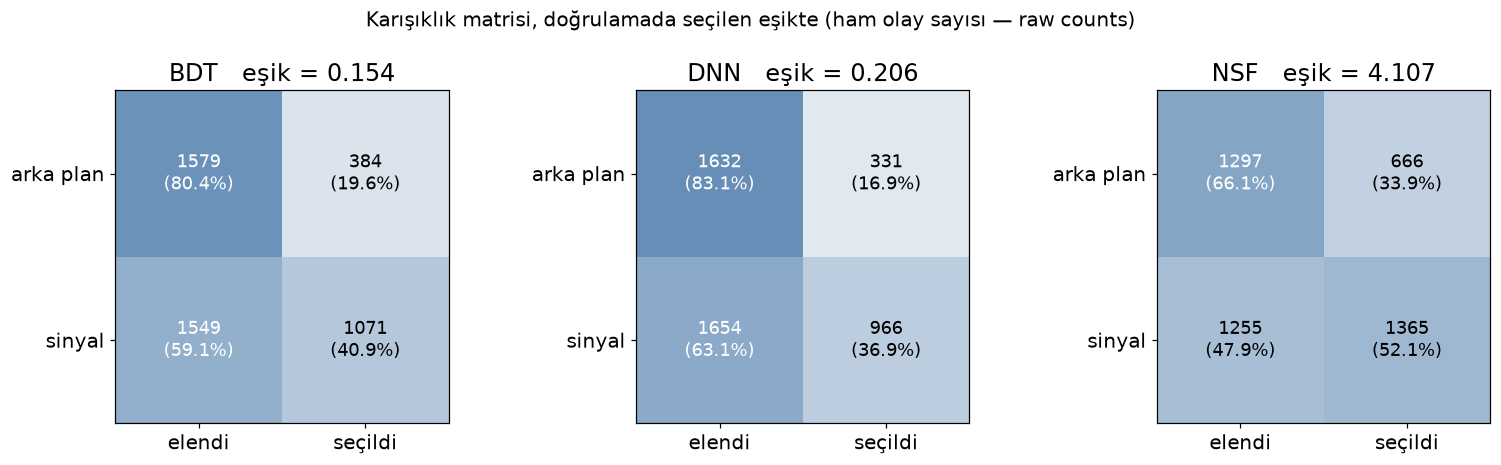

        esik  eps_S  eps_B       S        B   N_eff    Z_A
model                                                     
BDT    0.154  0.409  0.196  39.259   75.991  20.559  4.181
DNN    0.206  0.369  0.169  35.410   65.498  15.492  4.050
NSF    4.107  0.521  0.339  50.035  605.586  13.525  2.006


In [12]:
from matplotlib.colors import LinearSegmentedColormap

CMAP = LinearSegmentedColormap.from_list('mz', ['#ffffff', '#4878a8'])
fig, axes = plt.subplots(1, 3, figsize=(14.4, 4.3))
satirlar = []
son = results.iloc[-1]
for ax, m in zip(axes, MODELS):
    c = curves_all[-1][m]
    sb, ss, cut = c['sb'], c['ss'], c['cut']
    cm = np.array([[(sb <= cut).sum(), (sb > cut).sum()],
                   [(ss <= cut).sum(), (ss > cut).sum()]], float)
    oran = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(oran, cmap=CMAP, vmin=0, vmax=1)
    for a in range(2):
        for b in range(2):
            ax.text(b, a, f'{int(cm[a, b])}\n({oran[a, b]:.1%})',
                    ha='center', va='center', fontsize=12,
                    color='white' if oran[a, b] > 0.55 else 'black')
    ax.set_xticks([0, 1], ['elendi', 'seçildi'])
    ax.set_yticks([0, 1], ['arka plan', 'sinyal'])
    ax.set_title(f'{m}   eşik = {cut:.3f}')
    satirlar.append({'model': m, 'esik': cut, 'eps_S': son[f'epsS_{m}'],
                     'eps_B': son[f'epsB_{m}'], 'S': son[f'S_{m}'],
                     'B': son[f'B_{m}'], 'N_eff': son[f'Neff_{m}'],
                     'Z_A': son[f'Za_{m}']})
fig.suptitle('Karışıklık matrisi, doğrulamada seçilen eşikte '
             '(ham olay sayısı — raw counts)', fontsize=13)
fig.tight_layout()
fig.savefig(OUT + 'confusion_matrix.pdf')
plt.show()

nokta = pd.DataFrame(satirlar).set_index('model').round(3)
nokta.to_csv(OUT + 'working_point.csv')
print(nokta.to_string())

## 6a. Kaç öznitelik gerekli?

Ana karşılaştırma literatürden önceden seçilmiş 8 değişkeni kullanır. Burada aynı protokol (60/20/20, eşik doğrulamada, aynı fit fonksiyonları) dört farklı öznitelik kümesiyle tekrarlanır: elle seçilmiş 4'lü, tanı amaçlı 9'lu, literatür 8'lisi ve referans analizin tam 32'lik havuzu. Amaç en iyi kümeyi test kümesinden seçmek değil -- bu sızıntı olurdu -- bunun yerine 8'li seçimin boyut artırmaya duyarlı olup olmadığını ölçmektir.

In [13]:
F36 = ['met', 'met_phi', 'min_dphi_met_jets', 'dphi_met_jet1',
       'dphi_met_jet2', 'met_over_sqrtHT', 'hadronic_recoil_pt', 'm_ll',
       'Z_pt', 'Z_eta', 'Z_phi', 'dphi_Z_met', 'met_over_ptZ',
       'abs_met_minus_ptZ', 'abs_mll_minus_mZ', 'u_parallel', 'u_perp',
       'u_parallel_over_ptZ', 'u_perp_over_ptZ', 'lep1_pt', 'lep1_eta',
       'lep2_pt', 'lep2_eta', 'dR_ll', 'dphi_ll', 'lep1_reliso',
       'lep2_reliso', 'cos_theta_star', 'dphi_met_lep1', 'jet1_pt',
       'jet1_eta', 'jet2_pt', 'jet2_eta', 'has_jet1', 'has_jet2', 'n_jets']
POOL = [f for f in F36 if bkg[f].std() > 1e-9]
FEATURE_SETS = {
    'elle 4D': ['met', 'mT', 'dphi_Z_met', 'n_jets'],
    'tani 9D': ['met', 'mT', 'Z_pt', 'Z_eta', 'dphi_Z_met', 'dR_ll',
               'lep1_pt', 'lep2_pt', 'n_jets'],
    'literatur 8D': FEATURES,
    'makale 32D': POOL}
N_SEED_TARAMA = 3          # ana karsilastirmadan daha az: tarama amacli


def evaluate_features(F, seed):
    # evaluate_split ile ayni mantik, farkli oznitelik kumesi icin.
    b_tr, b_va, b_te = split3(bkg, seed)
    s_tr, s_va, s_te = split3(sig, seed)
    sc_ = StandardScaler().fit(b_tr[F])
    tf = lambda d: sc_.transform(d[F])
    jc = F.index('n_jets') if 'n_jets' in F else None

    def xyw(bd, sd):
        x = np.vstack([tf(bd), tf(sd)])
        y = np.r_[np.zeros(len(bd)), np.ones(len(sd))]
        w = np.r_[np.full(len(bd), .5 / len(bd)),
                  np.full(len(sd), .5 / len(sd))]
        return x, y, w

    x_tr, y_tr, w_tr = xyw(b_tr, s_tr)
    x_va, y_va, w_va = xyw(b_va, s_va)
    bdt_score, _ = fit_bdt(x_tr, y_tr, w_tr, x_va, y_va, w_va, seed)
    scorers = {'BDT': bdt_score,
              'DNN': fit_dnn(x_tr, y_tr, w_tr, x_va, y_va, w_va, seed)}
    fsm = fit_flow(tf(b_tr), tf(b_va), seed, jc)
    fdm = fit_flow(tf(s_tr), tf(s_va), seed, jc)
    scorers['NSF'] = lambda x: log_prob(fdm, x) - log_prob(fsm, x)

    wb_va, ws_va = b_va.weight.to_numpy(), s_va.weight.to_numpy()
    wb_te, ws_te = b_te.weight.to_numpy(), s_te.weight.to_numpy()
    out = {}
    for name, f in scorers.items():
        sb, ss = f(tf(b_te)), f(tf(s_te))
        sb_va, ss_va = f(tf(b_va)), f(tf(s_va))
        truth = np.r_[np.zeros(len(sb)), np.ones(len(ss))]
        cut = pick_cut(sb_va, ss_va, wb_va, ws_va, 1 / FRAC)
        _, za = apply_cut(cut, sb, ss, wb_te, ws_te, 1 / FRAC)
        sw = np.r_[wb_te, ws_te]
        out[f'auc_{name}'] = roc_auc_score(truth, np.r_[sb, ss],
                                           sample_weight=sw)
        out[f'Za_{name}'] = za
    return out


tarama = []
for ad, F in FEATURE_SETS.items():
    for seed in range(N_SEED_TARAMA):
        r = evaluate_features(F, seed)
        tarama.append({'set': ad, 'd': len(F), 'seed': seed, **r})
    print(f'  {ad:13s} ({len(F):2d}D) bitti', flush=True)

tarama = pd.DataFrame(tarama)
KOLON = [f'{k}_{m}' for k in ('auc', 'Za') for m in ('BDT', 'DNN', 'NSF')]
oznitelik_ozet = tarama.groupby(['set', 'd'])[KOLON].mean().round(3)
oznitelik_ozet.to_csv(OUT + 'feature_scan.csv')
print()
print(oznitelik_ozet.to_string())


  elle 4D       ( 4D) bitti


  tani 9D       ( 9D) bitti


  literatur 8D  ( 8D) bitti


  makale 32D    (32D) bitti



                 auc_BDT  auc_DNN  auc_NSF  Za_BDT  Za_DNN  Za_NSF
set          d                                                    
elle 4D      4     0.948    0.952    0.920   4.374   4.808   3.764
literatur 8D 8     0.960    0.963    0.880   4.642   4.711   1.831
makale 32D   32    0.960    0.960    0.936   4.213   4.602   2.754
tani 9D      9     0.956    0.958    0.908   4.254   4.411   2.011


## 6c. SM yoğunluğu nerede öğrenilmeli? (NSF'ye özgü tanı)

NSF'nin ayırt edici modellerin gerisinde kalması bir yöntem kusuru değil,
**istatistik kısıtı** olabilir: yoğunluk kestirimi sınıflandırmadan çok daha
fazla olay ister. Sinyal bölgesinde arka plan için etkin örneklem büyüklüğü
küçüktür; buna karşılık kontrol bölgesi (MET $<50$ GeV) aynı niceliğin
$\sim$220 katını taşır.

Ayrı bir koşumda (`_cr_flow.py`) SM yoğunluğu CR'de öğretilip skor SR'de
uygulandı. Sonuçlar `cr_vs_sr_flow.csv` dosyasındadır. Bu kurulum, BDT/DNN ile
**aynı eğitim olaylarını kullanmadığı için** yukarıdaki adil karşılaştırmaya
dahil edilmemiştir; yöntemsel bir gözlem olarak ayrı raporlanır. Karşı risk
açıktır: CR ve SR kinematik olarak ayrıktır, yani CR'de öğrenilen yoğunluk
SR'ye ekstrapole edilmektedir.

*Kaynak:* S. Rasineni, S. Chebrolu (mono-$Z$ makine ogrenmesi analizi);
B. Nachman, D. Shih, Phys. Rev. D **101** (2020) 075042.

In [14]:
# CR (MET<50) tazeden yuklenir; SR icin zaten yukaridaki bkg/sig kullanilir.
RS_F = ['met', 'mT', 'Z_pt', 'dphi_Z_met', 'dR_ll', 'n_jets']
CR_MAX = 60000
N_SEED_CR = 3

tum_bkg = load(BKG)
CR = tum_bkg[tum_bkg.met < 50].reset_index(drop=True)
CR['weight'] = cell_resample(CR, RS_F)
CR_SETS = {'elle 4D': ['met', 'mT', 'dphi_Z_met', 'n_jets'],
          'literatur 8D': FEATURES,
          'makale 32D': POOL}
print(f'CR {len(CR)} olay, SR {len(bkg)} olay, sinyal {len(sig)} olay')

cr_res = []
for seed in range(N_SEED_CR):
    b_tr, b_va, b_te = split3(bkg, seed)
    s_tr, s_va, s_te = split3(sig, seed)
    cr_s = CR.sample(n=min(CR_MAX, len(CR)), random_state=seed)
    c_tr, c_va = train_test_split(cr_s, test_size=.3, random_state=seed)
    satir = {'seed': seed}
    for ad, F in CR_SETS.items():
        jc = F.index('n_jets') if 'n_jets' in F else None
        sc_ = StandardScaler().fit(b_tr[F])
        tf = lambda d: sc_.transform(d[F])
        fdm = fit_flow(tf(s_tr), tf(s_va), seed, jc)
        for mod, (a_tr, a_va) in (('SR', (b_tr, b_va)), ('CR', (c_tr, c_va))):
            fsm = fit_flow(tf(a_tr), tf(a_va), seed, jc)
            sk = lambda d: log_prob(fdm, tf(d)) - log_prob(fsm, tf(d))
            sb, ss = sk(b_te), sk(s_te)
            cut = pick_cut(sk(b_va), sk(s_va), b_va.weight.to_numpy(),
                           s_va.weight.to_numpy(), 1 / FRAC)
            _, z = apply_cut(cut, sb, ss, b_te.weight.to_numpy(),
                             s_te.weight.to_numpy(), 1 / FRAC)
            truth = np.r_[np.zeros(len(sb)), np.ones(len(ss))]
            auc = roc_auc_score(truth, np.r_[sb, ss])
            satir[f'{ad}|{mod}'] = z
            satir[f'auc|{ad}|{mod}'] = auc
        print(f'  tohum {seed} {ad:13s} SR-eğitimli '
             f'{satir[f"{ad}|SR"]!s:>6.6s} | CR-eğitimli '
             f'{satir[f"{ad}|CR"]!s:>6.6s}', flush=True)
    cr_res.append(satir)

cr = pd.DataFrame(cr_res)
cr.to_csv(OUT + 'cr_vs_sr_flow.csv', index=False)
setler = [c for c in cr.columns if '|' in c and not c.startswith('auc')]
tablo = pd.DataFrame(
    {'Z_A': [cr[c].mean() for c in setler],
     'Z_A_sd': [cr[c].std() for c in setler],
     'AUC': [cr['auc|' + c].mean() for c in setler]},
    index=setler).round(3)
tablo.to_csv(OUT + 'cr_vs_sr_summary.csv')
print()
print(tablo.to_string())


DY                 N_gen=1315027  sum_w=20674966616.4  selected=275075  sigma=5932.0000 pb  yield=2937074.5  [onbellek]
ZZ                 N_gen=  63025  sum_w=  63025.0  selected= 17856  sigma=   0.5644 pb  yield=    371.0  [onbellek]
WZ                 N_gen=  95164  sum_w=  95164.0  selected=  6855  sigma=   4.1017 pb  yield=    685.5  [onbellek]
ttbar              N_gen=  56227  sum_w=  56227.0  selected=  1482  sigma=  76.6900 pb  yield=   4689.5  [onbellek]
tW_top             N_gen= 105600  sum_w= 105600.0  selected=   304  sigma=  38.0900 pb  yield=    254.4  [onbellek]
tW_antitop         N_gen= 110000  sum_w= 110000.0  selected=   339  sigma=  38.0600 pb  yield=    272.1  [onbellek]


CR 282045 olay, SR 9812 olay, sinyal 13097 olay


  tohum 0 elle 4D       SR-eğitimli 3.8100 | CR-eğitimli 4.3934


  tohum 0 literatur 8D  SR-eğitimli 1.7606 | CR-eğitimli 4.1506


  tohum 0 makale 32D    SR-eğitimli 2.8467 | CR-eğitimli 4.4519


  tohum 1 elle 4D       SR-eğitimli 3.9044 | CR-eğitimli 4.3484


... (2 outputs left out)

  tohum 2 elle 4D       SR-eğitimli 3.5760 | CR-eğitimli 3.9282


  tohum 2 literatur 8D  SR-eğitimli    nan | CR-eğitimli 4.1097


  tohum 2 makale 32D    SR-eğitimli 2.8451 | CR-eğitimli 4.7549



                   Z_A  Z_A_sd    AUC
elle 4D|SR       3.764   0.169  0.659
elle 4D|CR       4.223   0.257  0.668
literatur 8D|SR  1.831   0.099  0.639
literatur 8D|CR  4.123   0.024  0.667
makale 32D|SR    2.754   0.160  0.649
makale 32D|CR    4.636   0.162  0.679


## 6d. Aşırı öğrenme kontrolü

Ana tablodaki `asiri_ogrenme` sütunu (AUC$_{\rm eğitim}-$AUC$_{\rm test}$) zaten bir aşırı öğrenme ölçütüdür. Burada ek olarak eğitim/doğrulama/test skor dağılımları iki örneklemli Kolmogorov--Smirnov testiyle karşılaştırılır: $p<0.05$ ise eğitim ve test dağılımları istatistiksel olarak ayrışmış, yani model eğitim kümesini kısmen ezberlemiş demektir. Tek bölünme (tohum 0) üzerinde, 8 öznitelikli ana kurulumla.

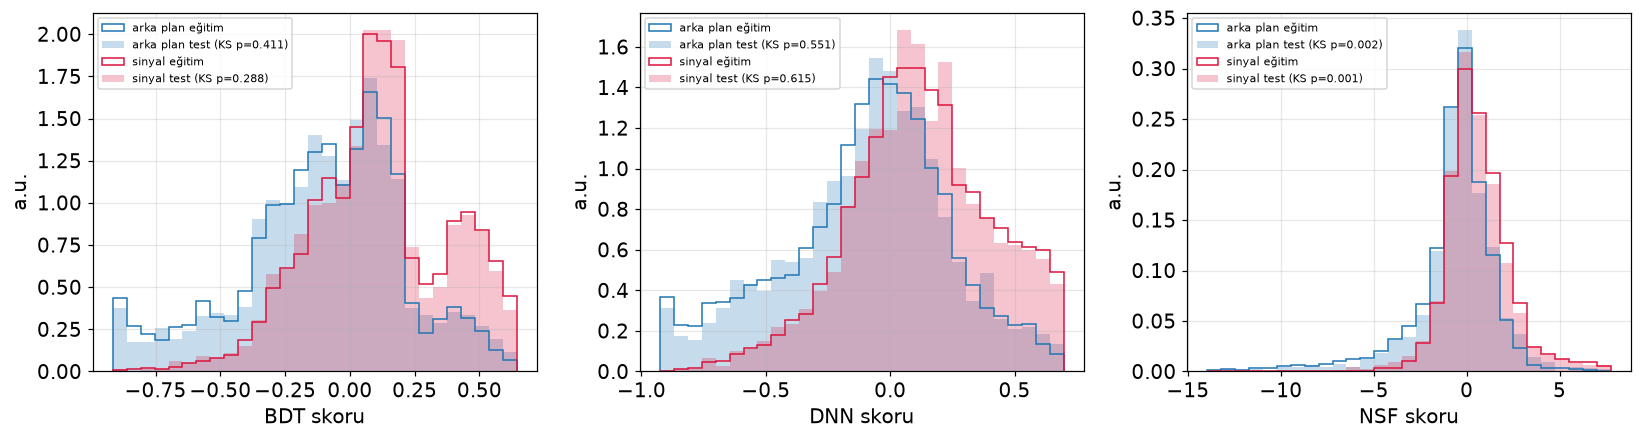

model     sinif     KS_p
  BDT arka plan 0.410847
  BDT    sinyal 0.288222
  DNN arka plan 0.551226
  DNN    sinyal 0.614858
  NSF arka plan 0.001926
  NSF    sinyal 0.000992


In [15]:
from scipy.stats import ks_2samp

b_tr0, b_va0, b_te0 = split3(bkg, 0)
s_tr0, s_va0, s_te0 = split3(sig, 0)
sc0 = StandardScaler().fit(b_tr0[FEATURES])
tf0 = lambda d: sc0.transform(d[FEATURES])
jc0 = FEATURES.index('n_jets')

x_tr0 = np.vstack([tf0(b_tr0), tf0(s_tr0)])
y_tr0 = np.r_[np.zeros(len(b_tr0)), np.ones(len(s_tr0))]
w_tr0 = np.r_[np.full(len(b_tr0), .5 / len(b_tr0)),
             np.full(len(s_tr0), .5 / len(s_tr0))]
x_va0 = np.vstack([tf0(b_va0), tf0(s_va0)])
y_va0 = np.r_[np.zeros(len(b_va0)), np.ones(len(s_va0))]
w_va0 = np.r_[np.full(len(b_va0), .5 / len(b_va0)),
             np.full(len(s_va0), .5 / len(s_va0))]

bdt0, _ = fit_bdt(x_tr0, y_tr0, w_tr0, x_va0, y_va0, w_va0, 0)
dnn0 = fit_dnn(x_tr0, y_tr0, w_tr0, x_va0, y_va0, w_va0, 0)
fsm0 = fit_flow(tf0(b_tr0), tf0(b_va0), 0, jc0)
fdm0 = fit_flow(tf0(s_tr0), tf0(s_va0), 0, jc0)
nsf0 = lambda x: log_prob(fdm0, x) - log_prob(fsm0, x)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ks_sonuc = []
for a, (ad, sk) in zip(ax, [('BDT', bdt0), ('DNN', dnn0), ('NSF', nsf0)]):
    tr_b, tr_s = sk(tf0(b_tr0)), sk(tf0(s_tr0))
    te_b, te_s = sk(tf0(b_te0)), sk(tf0(s_te0))
    lo, hi = np.percentile(np.r_[tr_b, tr_s, te_b, te_s], [.5, 99.5])
    bins = np.linspace(lo, hi, 30)
    for tr, te, renk, isim in ((tr_b, te_b, 'tab:blue', 'arka plan'),
                               (tr_s, te_s, 'crimson', 'sinyal')):
        p = ks_2samp(tr, te).pvalue
        ks_sonuc.append({'model': ad, 'sinif': isim, 'KS_p': p})
        a.hist(tr, bins=bins, density=True, histtype='step', color=renk,
              label=f'{isim} eğitim')
        a.hist(te, bins=bins, density=True, histtype='stepfilled', color=renk,
              alpha=.25, label=f'{isim} test (KS p={p:.3f})')
    a.set_xlabel(f'{ad} skoru')
    a.set_ylabel('a.u.')
    a.legend(fontsize=7)
    a.grid(alpha=.3)
plt.tight_layout()
plt.show()
ks_df = pd.DataFrame(ks_sonuc)
ks_df.to_csv(OUT + 'overtraining_ks.csv', index=False)
print(ks_df.to_string(index=False))


## 6e. Değişken önemi (permütasyon)

Her öznitelik test kümesinde sırayla karıştırılır, AUC'deki düşüş ölçülür. BDT ile değişken önemi, modelin skor için hangi girdilere en çok dayandığını gösterir; fizikle (örn. $E_T^{\rm miss}$'in baskın olması) tutarlılık bir sağlamadır.

/tmp/ipykernel_13049/1088022901.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  a.set_xticklabels(sira, rotation=35, ha='right')


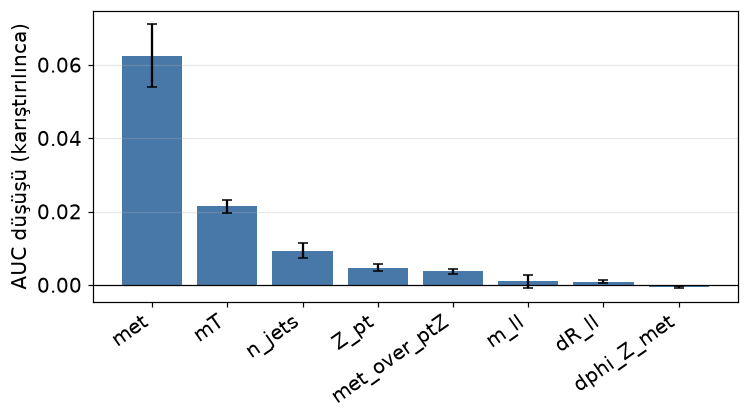

In [16]:
def perm_importance(score_fn, tf, b_te, s_te, F, n_tekrar=5, seed=0):
    """Her ozellik karistirilir, AUC dususu olculur.

    score_fn olceklenmis (StandardScaler sonrasi) girdi bekler; bu yuzden
    DataFrame'i once tf ile donusturup sonra score_fn'e verilir.
    """
    rng = np.random.default_rng(seed)
    yt = np.r_[np.zeros(len(b_te)), np.ones(len(s_te))]
    taban = roc_auc_score(yt, np.r_[score_fn(tf(b_te)), score_fn(tf(s_te))])
    sonuc = {}
    for f in F:
        dusus = []
        for _ in range(n_tekrar):
            bc, sc_ = b_te.copy(), s_te.copy()
            tum = np.r_[bc[f].to_numpy(), sc_[f].to_numpy()]
            rng.shuffle(tum)
            bc[f], sc_[f] = tum[:len(bc)], tum[len(bc):]
            auc = roc_auc_score(yt, np.r_[score_fn(tf(bc)), score_fn(tf(sc_))])
            dusus.append(taban - auc)
        sonuc[f] = (np.mean(dusus), np.std(dusus))
    return sonuc

imp = perm_importance(bdt0, tf0, b_te0, s_te0, FEATURES)
sira = sorted(FEATURES, key=lambda f: -imp[f][0])
fig, a = plt.subplots(figsize=(7, 4))
a.bar(sira, [imp[f][0] for f in sira], yerr=[imp[f][1] for f in sira],
     color='#4878a8', capsize=3)
a.axhline(0, color='k', lw=.8)
a.set_ylabel('AUC düşüşü (karıştırılınca)')
a.set_xticklabels(sira, rotation=35, ha='right')
a.grid(alpha=.3, axis='y')
plt.tight_layout()
plt.show()
pd.DataFrame({'ozellik': sira, 'onem': [imp[f][0] for f in sira],
             'sd': [imp[f][1] for f in sira]}).to_csv(
    OUT + 'permutation_importance.csv', index=False)


In [ ]:
def weighted_roc_auc(score_bkg, score_sig, weight_bkg, weight_sig):
    """Fiziksel agirliklarla ROC/AUC (sklearn negatif sample_weight kabul etmez -> |w|)."""
    y = np.r_[np.zeros(len(score_bkg)), np.ones(len(score_sig))]
    s = np.r_[score_bkg, score_sig]
    w = np.abs(np.r_[weight_bkg, weight_sig])
    auc = roc_auc_score(y, s, sample_weight=w)
    fpr, tpr, thr = roc_curve(y, s, sample_weight=w)
    return auc, fpr, tpr, thr


w_b, w_s, _ = test_w
for ad, c in curves_all[-1].items():
    auc, fpr, tpr, _ = weighted_roc_auc(c['sb'], c['ss'], w_b, w_s)
    print(f'{ad:4s}  AUC (agirlikli) = {auc:.4f}')


## 7. Yorum ve sınırlamalar

**Ne ölçüldü.** Üç yöntem aynı olaylar, öznitelikler ve bölünmelerle
karşılaştırıldı; sınıflandırma başarısı (AUC, SIC) ve fizik anlamlılığı ($Z_A$)
ayrı ayrı raporlandı. Sayılar yukarıdaki hücrelerin çıktısıdır.

**Sınırlamalar.**

1. **İstatistik.** Kullanılan DY örneği, CERN Open Data'daki 2890 dosyanın
   küçük bir alt kümesidir; olay başına ağırlık DY'de 41.2, $ZZ$'de 0.021
   düzeyindedir ($\sim$2000 kat fark). Bu, $Z_A$'nın baskın belirsizlik
   kaynağıdır ve beş bölünme arasındaki yayılımı açıklar.
2. **Negatif ağırlıklar.** DY'de %16.5; hücre yeniden örneklemesiyle yerel
   olarak eritildi (toplam ağırlık korunur), ancak yöntem kalan ağırlık
   dalgalanmasını tamamen gidermez.
3. **Sistematikler yok.** $Z_A$ yalnızca istatistiksel bir ölçüttür; jet enerji
   ölçeği, lepton verimliliği, ışınlılık ve pile-up belirsizlikleri dahil
   edilmemiştir. Dolayısıyla bu sayılar **keşif anlamlılığı veya dışlama
   limiti değildir**; yöntem karşılaştırma ölçütüdür.
4. **$w_{\rm PU}$ ve $SF_\mu$ = 1.** Gerçek çarpışma verisi kullanılmadığından
   uyulacak bir referans yoktur; ayrıca ortak çarpanlar $S/B$ oranında büyük
   ölçüde sadeleşir.
5. **Hiperparametre taraması yok.** Üç model de temel kurulumda bırakılmıştır;
   sıralama ayar bütçesine duyarlı olabilir.

### Veri Seti ve Modelleme Sınırlamaları

Bu analiz, CERN Open Data `RunIIFall15MiniAODv2` campaign verileri kullanılarak
saf bir Monte Carlo (MC) kapanış testi olarak tasarlanmıştır. Veri setinin
dönemsel kısıtları, analizin bazı güncel deneysel yaklaşımlardan
farklılaşmasına neden olmuştur:

* **Sinyal Modelleme.** Analizde 2015-dönemi EFT tarzı basitleştirilmiş
  modeller (axial, vector, scalar) kullanılmıştır. Güncel Run-2
  analizlerinde standart olan 2HDM+a veya modern $Z^\prime$ benchmark
  modelleri, kullanılan açık veri campaign'inde henüz erişilebilir
  olmadığı için sürece dahil edilememiştir.
* **Drell-Yan İstatistikleri ve Kesiklikler.** Drell-Yan arka planı için
  dilimli (binned) veri setleri bu campaign'de bulunmadığından, tek bir
  kapsayıcı (inclusive) NLO seti (`DYJetsToLL_M-50`) kullanılmıştır.
  Hesaplama kısıtları nedeniyle devasa veri setinin ($\sim$2890 dosya)
  yalnızca küçük bir alt kümesi işlenebilmiş, bu da olay başına yüksek
  ağırlıklar (ortalama 41.2) ve düşük istatistik kaynaklı dağılım
  kesiklikleri yaratmıştır. Bu yapay dalgalanmalar, $N_{\rm eff}$-uyarlamalı
  binleme ve hücre yeniden örnekleme yöntemleriyle sönümlenmiştir (bkz. §1a-2).
* **Veri-Güdümlü Arka Plan Kısıtı.** Gerçek çarpışma verisi kullanılmadığı
  için $t\bar{t}$ ve $tW$ arka planlarının farklı lezzet ($e\mu$) kontrol
  bölgelerinden veri-güdümlü (data-driven) yöntemlerle ölçülmesi mümkün
  olmamış; tüm arka planlar doğrudan simülasyondan alınmıştır.

**Sonraki adım.** DY'yi MC yerine veri kontrol bölgesinden kestirmek ve örneklem
istatistiğini artırmak; NSF için CR eğitimli kurulumun ekstrapolasyon hatasını
nicelemek.

*Kaynak:* CMS Collaboration, CERN Open Data Portal,
`RunIIFall15MiniAODv2` (DOI kayıtları `_dosyalar.json` içinde listelidir);
bu çalışma.